In [123]:
import numpy as np
import pandas as pd
from matplotlib.ticker import AutoMinorLocator, MaxNLocator
from itertools import combinations
from scipy.stats import gaussian_kde
import matplotlib.pyplot as plt
import ptitprince as pt
import seaborn as sns
import random
import math
from sklearn.impute import KNNImputer
from sklearn.linear_model import LinearRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

[1.1] Используя функцию multivariate
_
normal из numpy с любым random
_
state,
сгенерировать и зафиксировать датасет dfS00, в котором есть четыре количественных
(недискретных) признака и 1 класс размером 1000 объектов, для одной пары признаков
(A и B) которого задана корреляция r=+0.9, а остальные признаки не сопряжены друг с
другом.

In [124]:
n = 1000
cov = np.array([[1.0, 0.9, 0.0, 0.0],
                [0.9, 1.0, 0.0, 0.0],
                [0.0, 0.0, 1.0, 0.0],
                [0.0, 0.0, 0.0, 1.0],])
mean = [0.0, 0.0, 0.0, 0.0]

In [125]:
X = np.random.RandomState(42).multivariate_normal(mean=mean, cov=cov, size=n)

dfS00 = pd.DataFrame(X, columns=['A', 'B', 'C', 'D'])
dfS00['class'] = 0
dfS00

,A,B,C,D,class
0,-0.824697,-0.143577,0.647689,-0.138264,0
1,0.056621,0.399828,1.579213,-0.234137,0
2,0.561727,0.353447,-0.463418,0.542560,0
3,-0.110104,-0.361567,-1.724918,-1.913280,0
4,1.302986,0.671385,-0.908024,0.314247,0
...,...,...,...,...,...
995,-1.076841,-1.579283,3.152057,1.640615,0
996,-0.114151,-0.359313,0.553149,-2.082099,0
997,-1.769365,-1.980121,-1.689183,-0.774615,0
998,1.919104,1.931831,-2.065083,0.751099,0


[1.2] Вывести в табличной форме статистику по датасету, включая
- Размерность всего датасета (объекты и признаки) 
- Тип каждого признака
- Количество классов и объектов в каждом из классов 
- Иные оценки выборки
- Число объектов с NaN по классам 
- Число объектов с 0 по классам

In [126]:
summary_df = pd.DataFrame({
    'dtype':         dfS00.dtypes.astype(str),
    'Уникальных':    dfS00.nunique(),
    'Пропусков':     dfS00.isna().sum(),
    'Среднее':       dfS00.mean(),
    'Медиана':       dfS00.median(),
    'Стд.откл.':     dfS00.std(),
    'Дисперсия':     dfS00.var(),
    'Мин':           dfS00.min(),
    'Макс':          dfS00.max(),
    'Размах':        dfS00.max() - dfS00.min(),
    'IQR':           (dfS00.quantile(0.75, )
                      - dfS00.quantile(0.25, )),
    'Асимметрия':    dfS00.skew(),
    'Эксцесс':       dfS00.kurt(),
})

summary_df

,dtype,Уникальных,Пропусков,Среднее,Медиана,Стд.откл.,Дисперсия,Мин,Макс,Размах,IQR,Асимметрия,Эксцесс
A,float64,1000,0,-0.036576,-0.038811,0.961073,0.923661,-3.137198,3.198146,6.335344,1.257102,0.044454,0.046915
B,float64,1000,0,-0.023121,-0.031887,0.971135,0.943103,-3.184754,3.220093,6.404847,1.292792,0.039830,-0.031969
C,float64,1000,0,-0.008255,-0.007509,1.006075,1.012188,-3.241267,3.152057,6.393324,1.317581,0.013619,-0.008028
D,float64,1000,0,0.024828,0.020210,1.011884,1.023910,-2.896255,3.852731,6.748987,1.370918,0.106137,0.045857
class,int64,1,0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


[1.3] Выполнить 1D визуализацию датасета по каждому из признаков в форме raincloud
plot with jittering, рядом с которым в виде boxplot отображены медианы, межквартильные
размахи (IQR) и размахи (Range), с параметрами boxplot, которые можно заменять на
другие оценки выборки.

In [127]:
def raincloud_plot(mean=False, median=False, std=False, Range=False, IQR=False, mode=False,
                   FEATURES=['A', 'B', 'C', 'D'], COLORS=["#EE8588", "#F9D173", "#95E9F2", "#E2B7F4"],
                   STD_K=1.0):
    whis = (0,100) if Range else 0
    df_long = dfS00.melt(
        value_vars=FEATURES,
        var_name='feature',
        value_name='value',
    )

    fig, ax = plt.subplots(figsize=(9, 14))

    pt.half_violinplot(
        x='value', y='feature', data=df_long,
        palette=COLORS,
        inner=None,
        width=0.6,
        ax=ax,
    )

    for i, feat in enumerate(FEATURES):
        data = df_long[df_long['feature'] == feat]
        y = i + np.random.uniform(low=0.0, high=0.2, size=len(data))
        x = data['value']
        ax.scatter(x, y, color=COLORS[i], alpha=0.6, s=10, edgecolor='none')

    boxplot_data = [
        df_long[df_long['feature'] == feat]['value'].values
        for feat in FEATURES
    ]

    SHIFT = 0.1
    POSITIONS = [i + SHIFT for i in range(len(FEATURES))]

    ax.boxplot(
        boxplot_data,
        vert=False,
        positions=POSITIONS,
        manage_ticks=False,
        whis=whis,
        showfliers=False,
        # showmeans=mean,
        showcaps=True, capwidths=0.1,
        medianprops = {'linewidth': 1.5, 'color': "#000000"} if median else {'linewidth': 1.5, 'color': 'none'},
        boxprops    = {'linewidth': 1.5, 'color': "#000000"} if IQR else {'linewidth': 1.5, 'color': 'none'},
        capprops    = {'linewidth': 1.5, 'color': "#000000"} if Range else {'linewidth': 1.5, 'color': 'none'}, 
        # meanprops   = { 'markeredgecolor': '#000000', 'markersize': 7}
    )
    if mean:
        for i, feat in enumerate(FEATURES):
            vals = df_long.loc[df_long['feature'] == feat, 'value'].values
            if vals.size == 0:
                continue
            m = vals.mean()
            pos = i + SHIFT
            ax.plot([m, m], [pos - 0.18, pos + 0.18],
                    color="#00FF26", linewidth=2.0, zorder=5, label='mean' if i == 0 else None)

    if mode:
        for i, feat in enumerate(FEATURES):
            vals = df_long.loc[df_long['feature'] == feat, 'value'].values
            if vals.size < 2 or np.std(vals) == 0:
                continue
            kde = gaussian_kde(vals)
            xs = np.linspace(vals.min(), vals.max(), 500)
            mode_val = xs[np.argmax(kde(xs))]
            pos = i + SHIFT
            ax.plot([mode_val, mode_val], [pos - 0.18, pos + 0.18],
                    color="#FF8800", linewidth=2.0, zorder=5, label='mode' if i == 0 else None)
    if std:
        for i, feat in enumerate(FEATURES):
            vals = df_long.loc[df_long['feature'] == feat, 'value'].values
            if vals.size < 2:
                continue
            m = vals.mean()
            s = vals.std(ddof=1)
            lo, hi = m - STD_K * s, m + STD_K * s
            pos = i + SHIFT
            ax.plot([lo, hi], [pos, pos],
                    color="#0055FF", linewidth=1.8,
                    linestyle='--', zorder=4)
            ax.plot([lo, lo], [pos - 0.07, pos + 0.07],
                    color="#0055FF", linewidth=1.8, zorder=4)
            ax.plot([hi, hi], [pos - 0.07, pos + 0.07],
                    color="#0055FF", linewidth=1.8, zorder=4, label=f"std {STD_K} sigma")

    ax.set_xlabel('Значение', fontsize=15)
    ax.set_ylabel('Признак', fontsize=15)
    ax.set_title('Raincloud plot по признакам A, B, C, D', fontsize=18)
    ax.tick_params(labelsize=13)

    handles, labels = ax.get_legend_handles_labels()
    seen = {}
    for h, l in zip(handles, labels):
        if l not in seen and not l.startswith('_'):
            seen[l] = h
    ax.legend(seen.values(), seen.keys(),
            loc='lower right', fontsize=11, frameon=True)

    plt.tight_layout()
    plt.show()

/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/1680718647.py:35: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


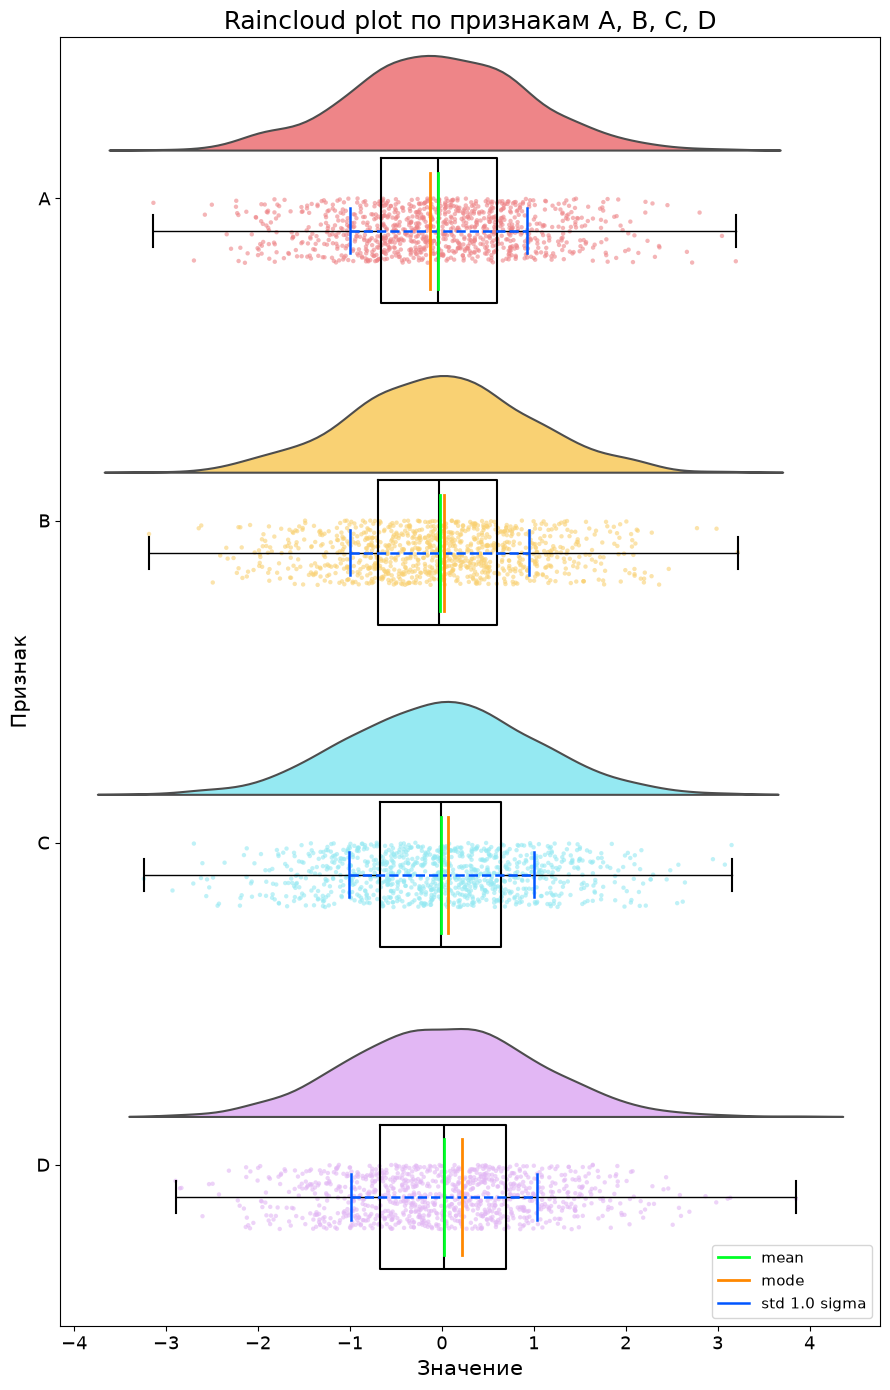

In [128]:
raincloud_plot(mean=True, median=True, Range=True, IQR=True, mode=True, std=True, STD_K=1.0)

[1.4] Выполнить 2D визуализацию датасета по всем парам выбранных переменных с
использованием scatterplot с параметрами визуализации, регулируемыми пользователем
(цвета и толщины осей, число/шаг больших и малых рисок осей, сетка пространства,
квадратность формы каждого рисунка, размер и тип шрифтов каждого типа подписей,
отключаемость легенд и заглавий, прозрачность объектов), на которых отображены:
- на графиках разных пар признаков объекты классов разными по форме/цвету точками;
- на графиках с одной и той же парой переменных 
- диаграммы плотности распределения
каждого класса по оси признака разными по цвету/прозрачности.

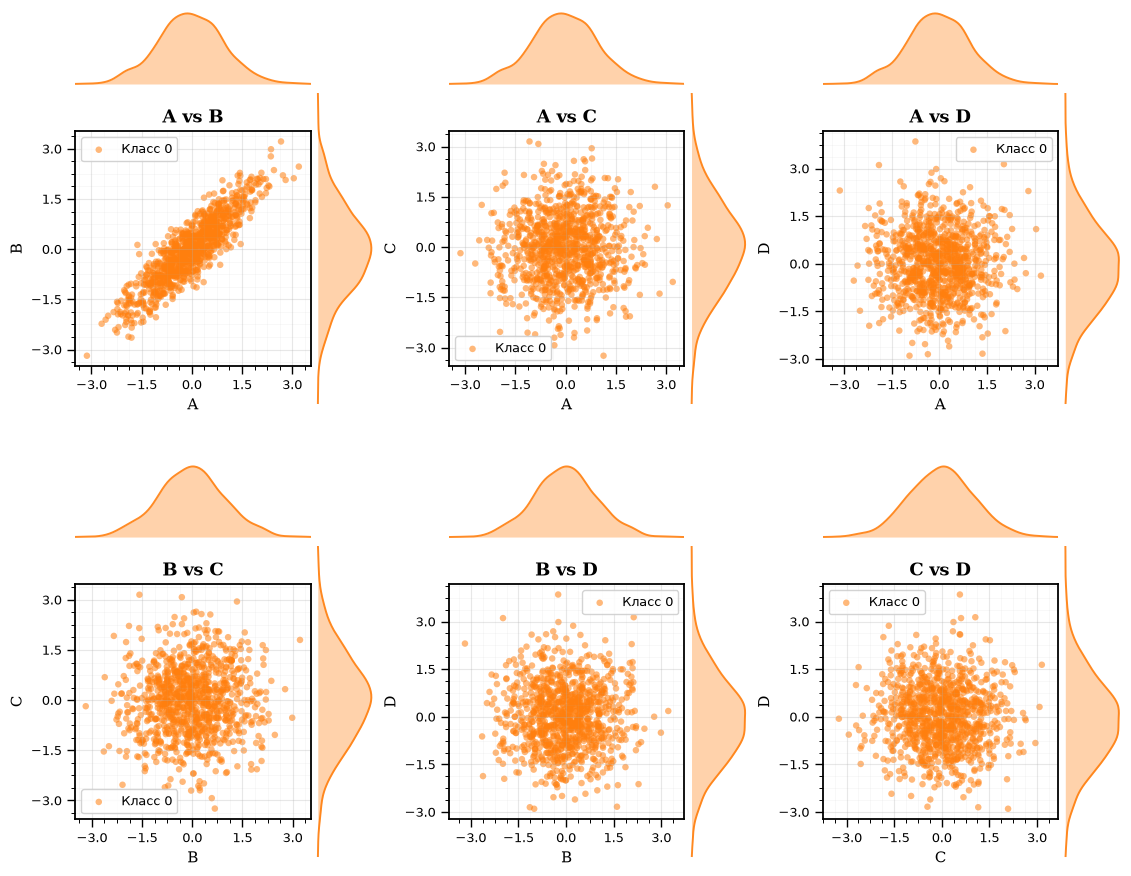

In [129]:
def plot_2d_visualization(
    df,
    features,
    class_column='class',
    figsize=(16, 16),
    n_classes=None,
    colors=None,
    markers=None,
    axis_linewidth=1.5,
    tick_width=1.2,
    tick_length_major=6,
    tick_length_minor=3,
    n_major_ticks=5,
    minor_per_major=4,
    grid=True,
    grid_alpha=0.3,
    grid_major_lw=0.8,
    grid_minor_lw=0.4,
    square=True,
    title_fontsize=14,
    title_fontweight='bold',
    title_fontfamily='DejaVu Sans',
    label_fontsize=12,
    label_fontfamily='DejaVu Sans',
    tick_fontsize=10,
    tick_fontfamily='DejaVu Sans',
    legend_fontsize=10,
    legend_fontfamily='DejaVu Sans',
    show_legend=True,
    show_title=True,
    alpha=0.6,
    marker_size=30,
    show_density=True,
    show_density_x=True,
    show_density_y=True,
    density_alpha=0.35,
    density_linealpha=0.9,
    density_linewidth=1.5,
    density_bins=200,
):
    classes_all = sorted(df[class_column].unique())
    n_classes_data = len(classes_all)

    if n_classes is None:
        n_classes = n_classes_data
    if n_classes > n_classes_data:
        n_classes = n_classes_data
    classes = classes_all[:n_classes]

    if colors is None:
        colors = [plt.cm.tab10(i % 10) for i in range(n_classes)]
    else:
        if isinstance(colors, str):
            colors = [colors]
        else:
            colors = list(colors)
        if len(colors) < n_classes:
            colors = [colors[i % len(colors)] for i in range(n_classes)]
        colors = colors[:n_classes]

    _default_markers = ['o', 's', '^', 'D', 'v', '<', '>', 'p',
                        'h', '*', 'X', 'P', '8', 'd', 'H', '+', 'x', '1', '2']
    if markers is None:
        markers = [_default_markers[i % len(_default_markers)]
                   for i in range(n_classes)]
    else:
        if isinstance(markers, str):
            markers = [markers]
        else:
            markers = list(markers)
        if len(markers) < n_classes:
            markers = [markers[i % len(markers)] for i in range(n_classes)]
        markers = markers[:n_classes]

    pairs = list(combinations(features, 2))
    n_pairs = len(pairs)
    if n_pairs == 0:
        raise ValueError("Нужно минимум 2 признака для построения пар.")

    n_cols = int(np.ceil(np.sqrt(n_pairs)))
    n_rows = int(np.ceil(n_pairs / n_cols))

    use_top = show_density and show_density_x
    use_right = show_density and show_density_y

    h_ratios = [1, 4] if use_top else [1]
    w_ratios = [4, 1] if use_right else [1]

    inner_rows = 2 if use_top else 1
    inner_cols = 2 if use_right else 1

    fig = plt.figure(figsize=figsize)
    outer = fig.add_gridspec(n_rows, n_cols, hspace=0.15, wspace=0.25)

    for idx, (f1, f2) in enumerate(pairs):
        r, c = divmod(idx, n_cols)

        inner = outer[r, c].subgridspec(
            inner_rows, inner_cols,
            width_ratios=w_ratios,
            height_ratios=h_ratios,
            hspace=0.03, wspace=0.03
        )

        if use_top and use_right:
            ax_top = fig.add_subplot(inner[0, 0])
            ax_main = fig.add_subplot(inner[1, 0])
            ax_right = fig.add_subplot(inner[1, 1])
        elif use_top:
            ax_top = fig.add_subplot(inner[0, 0])
            ax_main = fig.add_subplot(inner[1, 0])
            ax_right = None
        elif use_right:
            ax_top = None
            ax_main = fig.add_subplot(inner[0, 0])
            ax_right = fig.add_subplot(inner[0, 1])
        else:
            ax_top = None
            ax_main = fig.add_subplot(inner[0, 0])
            ax_right = None

        if ax_top is not None:
            ax_top.sharex(ax_main)
        if ax_right is not None:
            ax_right.sharey(ax_main)

        for i, cls in enumerate(classes):
            sub = df[df[class_column] == cls]
            ax_main.scatter(
                sub[f1], sub[f2],
                c=[colors[i]], marker=markers[i],
                s=marker_size, alpha=alpha,
                edgecolors='none',
                label=f'Класс {cls}'
            )

        if square:
            ax_main.set_aspect('equal', adjustable='box')
            x0, x1 = ax_main.get_xlim()
            y0, y1 = ax_main.get_ylim()
            xc = 0.5 * (x0 + x1)
            yc = 0.5 * (y0 + y1)
            half = 0.5 * max(x1 - x0, y1 - y0)
            ax_main.set_xlim(xc - half, xc + half)
            ax_main.set_ylim(yc - half, yc + half)

        if show_density:
            x_min, x_max = ax_main.get_xlim()
            y_min, y_max = ax_main.get_ylim()

            for i, cls in enumerate(classes):
                vals_x = df.loc[df[class_column] == cls, f1].dropna().values
                vals_y = df.loc[df[class_column] == cls, f2].dropna().values

                if use_top and len(vals_x) > 1 and np.ptp(vals_x) > 0:
                    kde_x = gaussian_kde(vals_x)
                    x_grid = np.linspace(x_min, x_max, density_bins)
                    ax_top.fill_between(x_grid, 0, kde_x(x_grid),
                                        color=colors[i], alpha=density_alpha, linewidth=0)
                    ax_top.plot(x_grid, kde_x(x_grid),
                                color=colors[i], alpha=density_linealpha, linewidth=density_linewidth)

                if use_right and len(vals_y) > 1 and np.ptp(vals_y) > 0:
                    kde_y = gaussian_kde(vals_y)
                    y_grid = np.linspace(y_min, y_max, density_bins)
                    ax_right.fill_betweenx(y_grid, 0, kde_y(y_grid),
                                           color=colors[i], alpha=density_alpha, linewidth=0)
                    ax_right.plot(kde_y(y_grid), y_grid,
                                  color=colors[i], alpha=density_linealpha, linewidth=density_linewidth)

            for ax_p, enabled in ((ax_top, use_top), (ax_right, use_right)):
                if enabled:
                    ax_p.set_xticks([])
                    ax_p.set_yticks([])
                    ax_p.set_xlabel('')
                    ax_p.set_ylabel('')
                    ax_p.set_title('')
                    for s in ax_p.spines.values():
                        s.set_visible(False)
                    ax_p.set_facecolor('none')
                    ax_p.tick_params(
                        axis='both', which='both',
                        bottom=False, top=False,
                        left=False, right=False,
                        labelbottom=False, labeltop=False,
                        labelleft=False, labelright=False,
                    )

        ax_main.set_xlabel(f1, fontsize=label_fontsize, fontfamily=label_fontfamily)
        ax_main.set_ylabel(f2, fontsize=label_fontsize, fontfamily=label_fontfamily)

        ax_main.tick_params(axis='both', which='major',
                            labelsize=tick_fontsize, length=tick_length_major, width=tick_width)
        ax_main.tick_params(axis='both', which='minor',
                            length=tick_length_minor, width=tick_width * 0.7)
        for lbl in ax_main.get_xticklabels() + ax_main.get_yticklabels():
            lbl.set_fontfamily(tick_fontfamily)

        ax_main.xaxis.set_major_locator(MaxNLocator(n_major_ticks))
        ax_main.yaxis.set_major_locator(MaxNLocator(n_major_ticks))
        ax_main.xaxis.set_minor_locator(AutoMinorLocator(minor_per_major))
        ax_main.yaxis.set_minor_locator(AutoMinorLocator(minor_per_major))

        if grid:
            ax_main.grid(True, which='major', alpha=grid_alpha, linewidth=grid_major_lw)
            ax_main.grid(True, which='minor', alpha=grid_alpha * 0.5, linewidth=grid_minor_lw)

        for spine in ax_main.spines.values():
            spine.set_linewidth(axis_linewidth)

        if show_title:
            ax_main.set_title(f'{f1} vs {f2}', fontsize=title_fontsize,
                              fontweight=title_fontweight, fontfamily=title_fontfamily)

        if show_legend:
            ax_main.legend(fontsize=legend_fontsize, loc='best', framealpha=0.85,
                           prop={'family': legend_fontfamily, 'size': legend_fontsize})

    # Заполняем пустые ячейки внешней сетки
    for k in range(n_pairs, n_rows * n_cols):
        r, c = divmod(k, n_cols)
        ax_empty = fig.add_subplot(outer[r, c])
        ax_empty.axis('off')

    fig.subplots_adjust(hspace=0.15, wspace=0.2, right=0.93)

    plt.show()
    return fig


fig = plot_2d_visualization(
    df=dfS00,                                                 # датасет
    features=['A', 'B', 'C', 'D'],                            # список признаков для построения всех пар
    class_column='class',                                     # имя колонки с классом
    figsize=(13, 11),                                         # размер всего полотна (ширина, высота) в дюймах
    n_classes=1,                                              # число классов (если None — берётся из данных)
    colors=['tab:orange'],                                    # цвета классов (если меньше — циклически повторятся, если больше — обрежутся)
    markers=['o'],                                            # маркеры (формы точек) классов (аналогично цветам)
    axis_linewidth=1.3,                                       # толщина линий осей (рамки каждого графика)
    tick_width=1.0,                                           # толщина рисок
    tick_length_major=6,                                      # длина больших рисок
    tick_length_minor=3,                                      # длина малых рисок
    n_major_ticks=5,                                          # число больших рисок на ось
    minor_per_major=4,                                        # число малых рисок между большими
    grid=True,                                                # включение сетки пространства
    grid_alpha=0.3,                                           # прозрачность сетки
    grid_major_lw=0.8,                                        # толщина линий большой сетки
    grid_minor_lw=0.4,                                        # толщина линий малой сетки
    square=True,                                              # квадратность формы каждого рисунка
    title_fontsize=13,                                        # размер шрифта заголовка
    title_fontweight='bold',                                  # насыщенность шрифта заголовка
    title_fontfamily='DejaVu Serif',                          # семейство шрифта заголовка
    label_fontsize=11,                                        # размер шрифта подписей осей
    label_fontfamily='DejaVu Serif',                          # семейство шрифта подписей осей
    tick_fontsize=9,                                          # размер шрифта отметок осей
    tick_fontfamily='DejaVu Sans Mono',                       # семейство шрифта отметок осей
    legend_fontsize=9,                                        # размер шрифта легенды
    legend_fontfamily='DejaVu Sans',                          # семейство шрифта легенды
    show_legend=True,                                         # включение легенды
    show_title=True,                                          # включение заголовка
    alpha=0.55,                                               # прозрачность точек
    marker_size=22,                                           # размер точек
    show_density=True,                                        # включение диаграмм плотности
    show_density_x=True,                                      # включение плотности по оси X
    show_density_y=True,                                      # включение плотности по оси Y
    density_alpha=0.35,                                       # прозрачность заливки плотности
    density_linealpha=0.9,                                    # прозрачность линии плотности
    density_linewidth=1.4,                                    # толщина линии плотности
    density_bins=200,                                         # число точек сетки для KDE
)

[1.5] Используя коэффициенты корреляции Пирсона и Спирмана, в форме heat-map
таблицы оценить степень сопряженности пар признаков-переменных:
- на всем датасете 
- в каждом отдельном классе датасета.

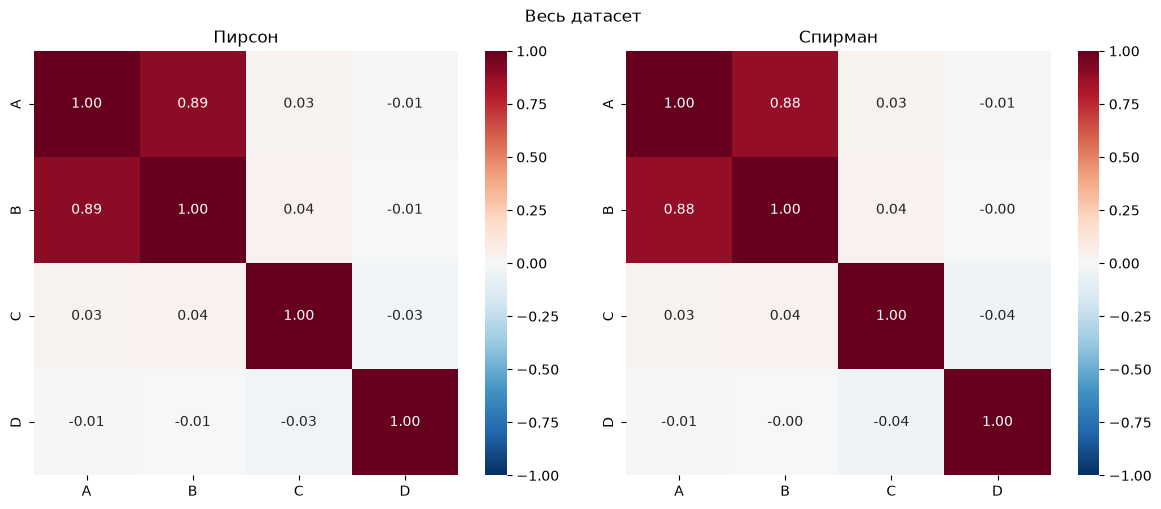

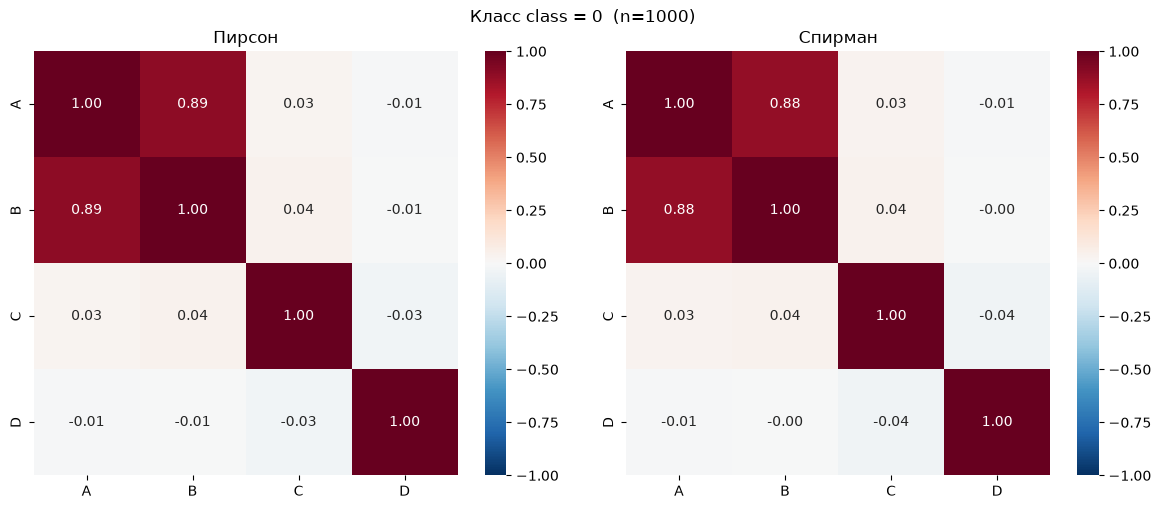

In [130]:
FEATURES = ['A', 'B', 'C', 'D']
KW = dict(annot=True, fmt='.2f', cmap='RdBu_r',
          vmin=-1, vmax=1, center=0, square=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Весь датасет')
sns.heatmap(dfS00[FEATURES].corr(method='pearson'),  ax=axes[0], **KW).set_title('Пирсон')
sns.heatmap(dfS00[FEATURES].corr(method='spearman'), ax=axes[1], **KW).set_title('Спирман')
plt.tight_layout()
plt.show()


for cls in sorted(dfS00['class'].unique()):
    sub = dfS00[dfS00['class'] == cls]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    fig.suptitle(f'Класс {'class'} = {cls}  (n={len(sub)})')
    sns.heatmap(sub[FEATURES].corr(method='pearson'),  ax=axes[0], **KW).set_title('Пирсон')
    sns.heatmap(sub[FEATURES].corr(method='spearman'), ax=axes[1], **KW).set_title('Спирман')
    plt.tight_layout()
    plt.show()

[1.6] На основе исходного датасета dfS00 клонировать набор датасетов dfSdXX, в
которых из исходного датасета случайным образом удалено значение заданного
пользователем числа ячеек (0%, 1%, 2%, 5%, 10%, 20%, 50%, 80%). Для выбираемой
пары признаков (исходно A+B) визуализировать каждый датасет dfSdXX как панно mxn
рисунков scatterplot.

In [131]:
def drop_random_cells(df, per, seed=42, target_col='class'):
    random.seed(seed)
    df = df.copy()
    n_rows, n_cols = df.shape
    
    if target_col in df.columns:
        protected_idx = df.columns.get_loc(target_col)
        allowed_cols = [c for c in range(n_cols) if c != protected_idx]
    else:
        allowed_cols = list(range(n_cols))
    
    n_allowed = len(allowed_cols)
    total_cells = n_rows * n_allowed
    m = int(math.ceil(total_cells * per / 100))
    
    flat = random.sample(range(total_cells), m)
    for i in flat:
        r = i // n_allowed
        c = allowed_cols[i % n_allowed]
        df.iloc[r, c] = np.nan
    
    return df

dfS01 = drop_random_cells(dfS00, 1)
dfS02 = drop_random_cells(dfS00, 2)
dfS05 = drop_random_cells(dfS00, 5)
dfS10 = drop_random_cells(dfS00, 10)
dfS20 = drop_random_cells(dfS00, 20)
dfS50 = drop_random_cells(dfS00, 50)
dfS80 = drop_random_cells(dfS00, 80)

dfS50

,A,B,C,D,class
0,-0.824697,NaN,NaN,-0.138264,0
1,NaN,0.399828,NaN,-0.234137,0
2,NaN,0.353447,NaN,NaN,0
3,-0.110104,NaN,NaN,-1.913280,0
4,1.302986,0.671385,-0.908024,0.314247,0
...,...,...,...,...,...
995,-1.076841,-1.579283,3.152057,NaN,0
996,-0.114151,-0.359313,0.553149,NaN,0
997,-1.769365,-1.980121,-1.689183,NaN,0
998,NaN,1.931831,-2.065083,NaN,0


0%


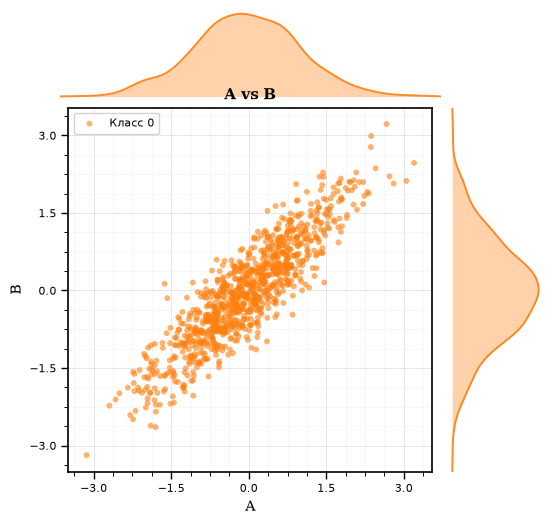

1%


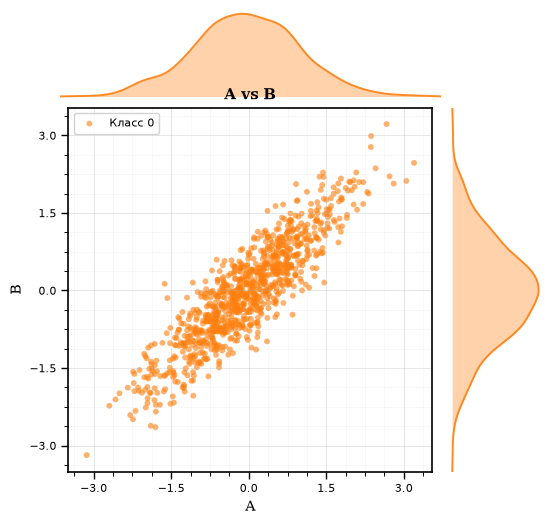

2%


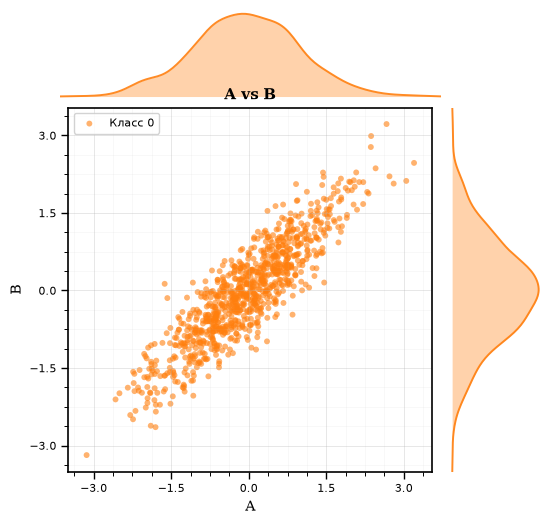

5%


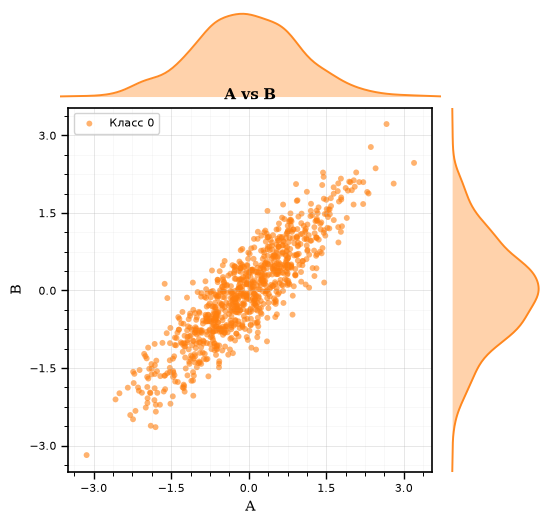

10%


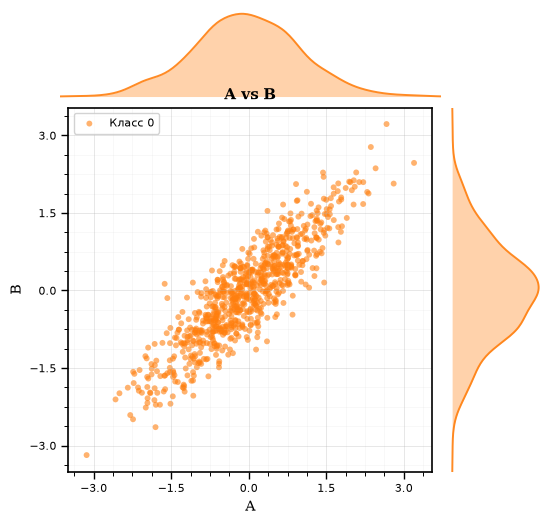

20%


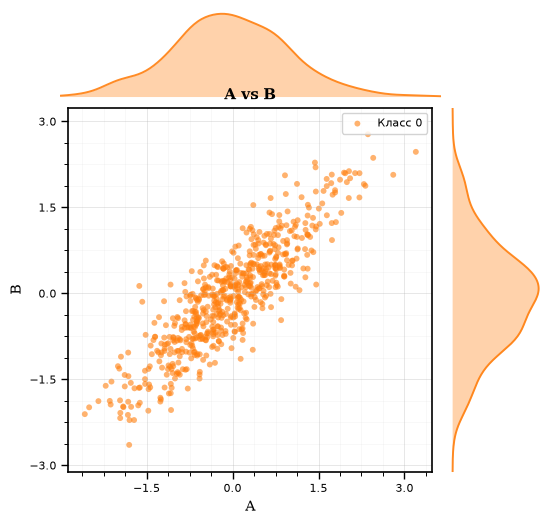

50%


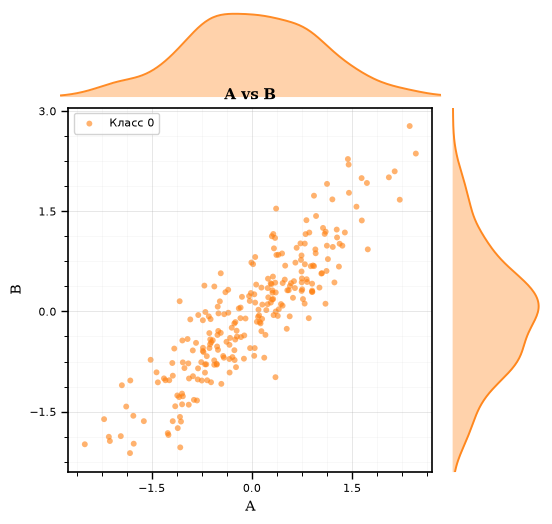

80%


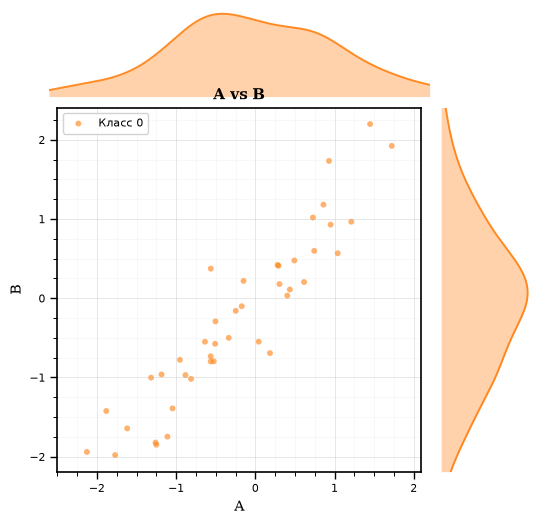

In [132]:
datasets_dfSdXX = {
    '0%':  dfS00,
    '1%':  dfS01,
    '2%':  dfS02,
    '5%':  dfS05,
    '10%': dfS10,
    '20%': dfS20,
    '50%': dfS50,
    '80%': dfS80,
}

for name, df_ in datasets_dfSdXX.items():
    print(name)
    plot_2d_visualization(
        df=df_,
        features=['A', 'B'],
        class_column='class',
        figsize=(6, 6),
        n_classes=1,
        colors=['tab:orange'],
        markers=['o'],
        axis_linewidth=1.2,
        tick_width=1.0,
        tick_length_major=5,
        tick_length_minor=3,
        n_major_ticks=5,
        minor_per_major=4,
        grid=True, grid_alpha=0.3,
        grid_major_lw=0.7, grid_minor_lw=0.4,
        square=True,
        title_fontsize=11, title_fontweight='bold',
        title_fontfamily='DejaVu Serif',
        label_fontsize=10, label_fontfamily='DejaVu Serif',
        tick_fontsize=8,   tick_fontfamily='DejaVu Sans Mono',
        legend_fontsize=8, legend_fontfamily='DejaVu Sans',
        show_legend=True,
        show_title=True,
        alpha=0.6, marker_size=18,
        show_density=True, show_density_x=True, show_density_y=True,
        density_alpha=0.35, density_linealpha=0.9,
        density_linewidth=1.4, density_bins=200,
    )

[1.7] На основе всех датасетов dfSdXX сгенерировать соответствующие датасеты
dfSdXXmed, в которых пропуски заполнены медианой. Для выбираемой пары признаков
(исходно A+B) визуализировать панно mxn рисунков scatterplot для всех dfSdXXmed и
вывести как heatmap корреляции Пирсона как в пункте [1.5]

In [133]:
def dfSdXXmed(df_):
    df = df_.copy()
    median_valA = df['A'].median()
    median_valB = df['B'].median()
    median_valC = df['C'].median()
    median_valD = df['D'].median()

    df['A'] = df['A'].fillna(median_valA)
    df['B'] = df['B'].fillna(median_valB)
    df['C'] = df['C'].fillna(median_valC)
    df['D'] = df['D'].fillna(median_valD)

    return df

dfSd01med = dfSdXXmed(dfS01)
dfSd02med = dfSdXXmed(dfS02)
dfSd05med = dfSdXXmed(dfS05)
dfSd10med = dfSdXXmed(dfS10)
dfSd20med = dfSdXXmed(dfS20)
dfSd50med = dfSdXXmed(dfS50)
dfSd80med = dfSdXXmed(dfS80)

1%


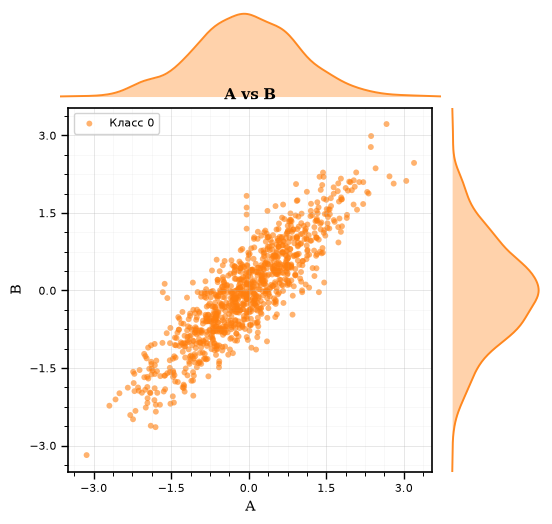

2%


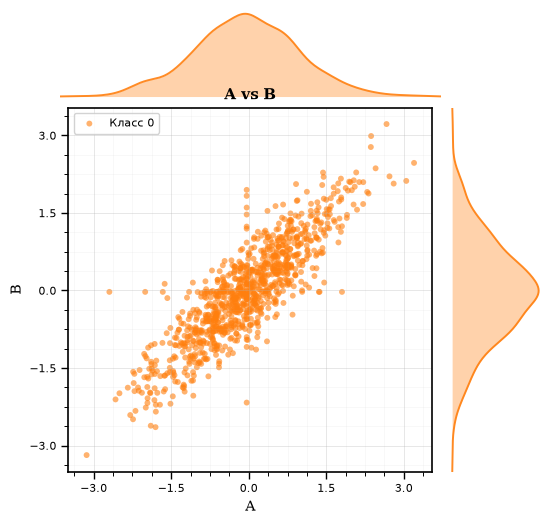

5%


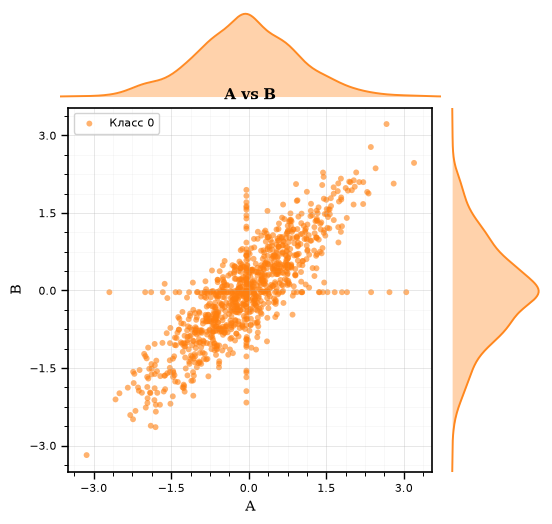

10%


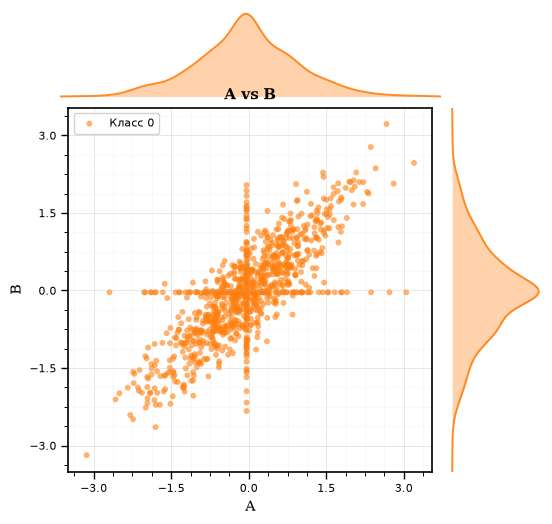

20%


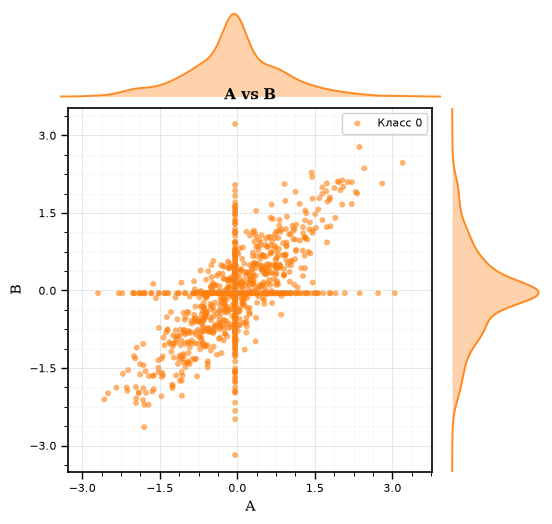

50%


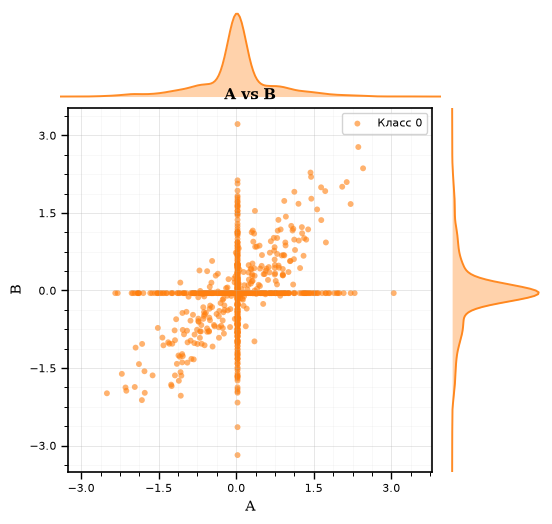

80%


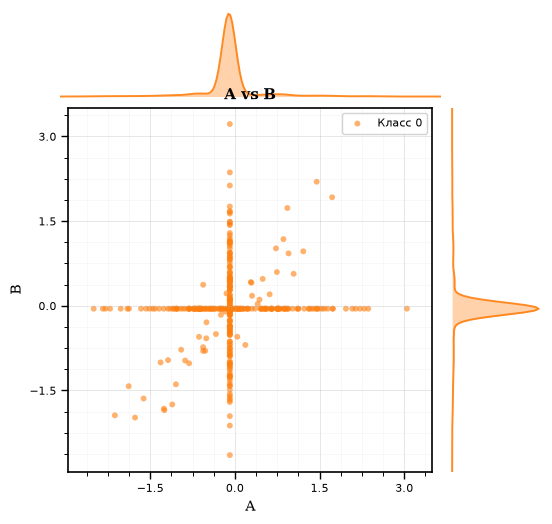

In [134]:
datasets_dfSdXXmed = {
    '1%':  dfSd01med,
    '2%':  dfSd02med,
    '5%':  dfSd05med,
    '10%': dfSd10med,
    '20%': dfSd20med,
    '50%': dfSd50med,
    '80%': dfSd80med,
}

for name, df_ in datasets_dfSdXXmed.items():
    print(name)
    plot_2d_visualization(
        df=df_,
        features=['A', 'B'],
        class_column='class',
        figsize=(6, 6),
        n_classes=1,
        colors=['tab:orange'],
        markers=['o'],
        axis_linewidth=1.2,
        tick_width=1.0,
        tick_length_major=5,
        tick_length_minor=3,
        n_major_ticks=5,
        minor_per_major=4,
        grid=True, grid_alpha=0.3,
        grid_major_lw=0.7, grid_minor_lw=0.4,
        square=True,
        title_fontsize=11, title_fontweight='bold',
        title_fontfamily='DejaVu Serif',
        label_fontsize=10, label_fontfamily='DejaVu Serif',
        tick_fontsize=8,   tick_fontfamily='DejaVu Sans Mono',
        legend_fontsize=8, legend_fontfamily='DejaVu Sans',
        show_legend=True,
        show_title=True,
        alpha=0.6, marker_size=18,
        show_density=True, show_density_x=True, show_density_y=True,
        density_alpha=0.35, density_linealpha=0.9,
        density_linewidth=1.4, density_bins=200,
    )

1%


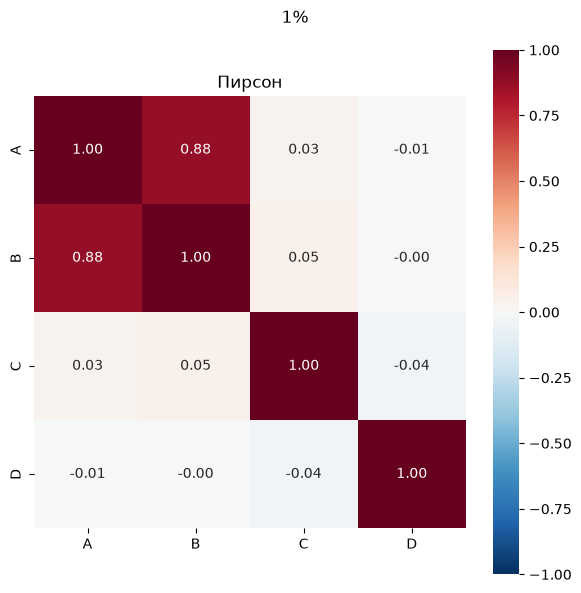

2%


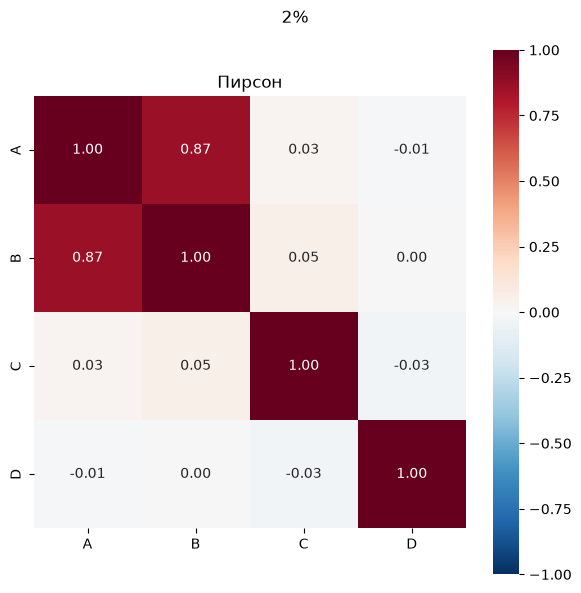

5%


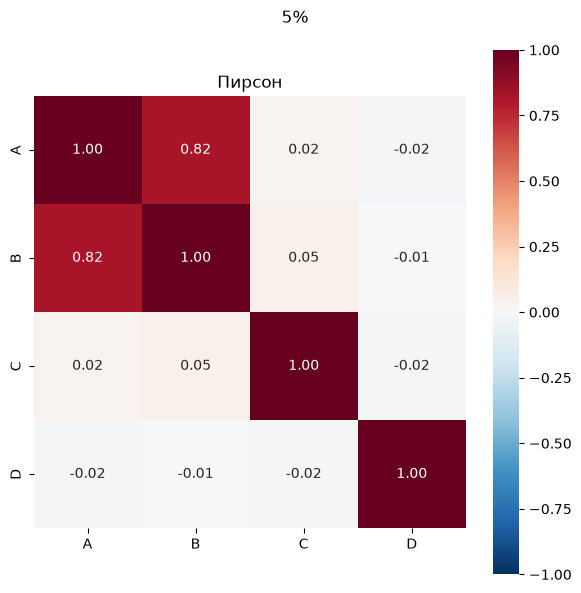

10%


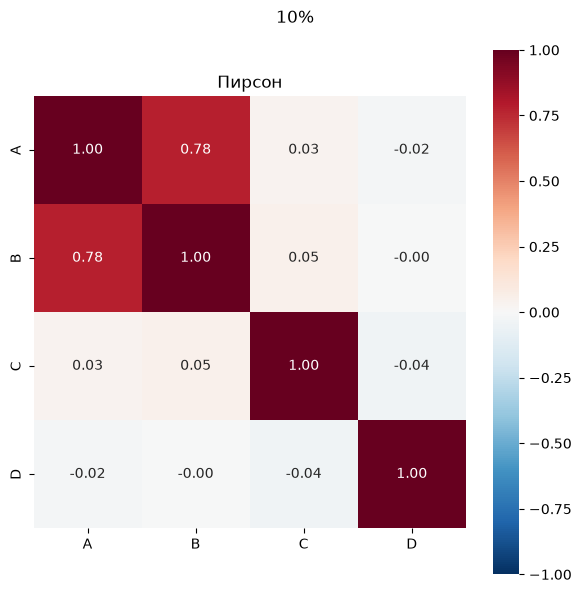

20%


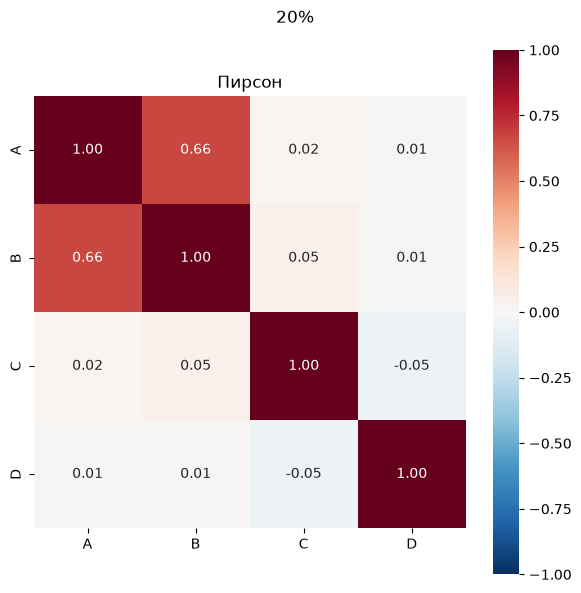

50%


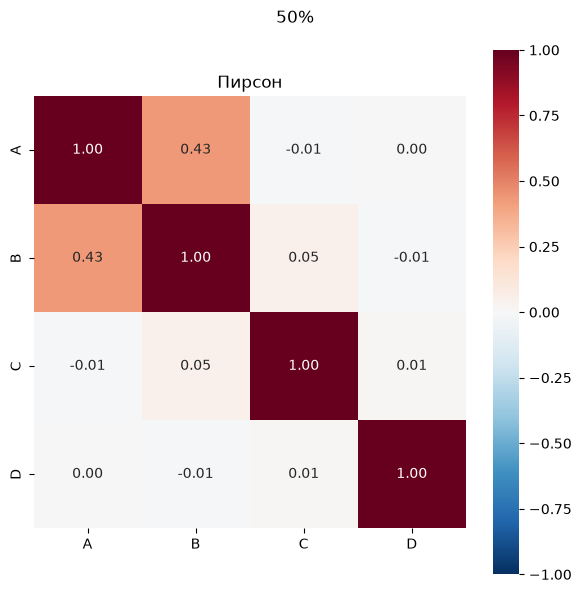

80%


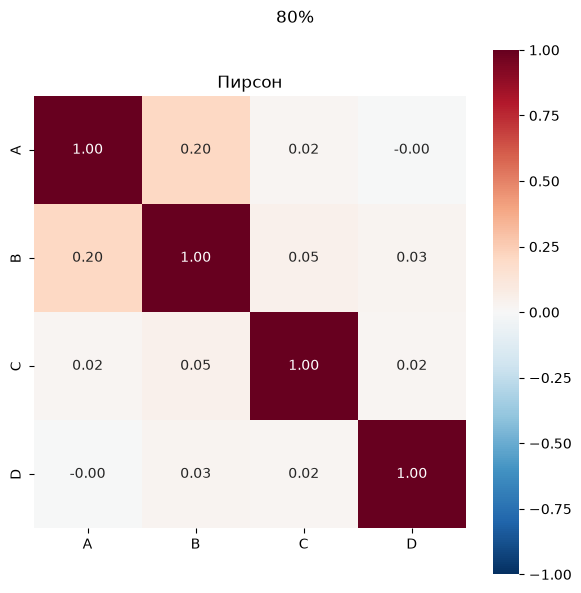

In [135]:
FEATURES = ['A', 'B', 'C', 'D']
KW = dict(annot=True, fmt='.2f', cmap='RdBu_r',
          vmin=-1, vmax=1, center=0, square=True)

for name, df_ in datasets_dfSdXXmed.items():
    print(name)
    fig, ax = plt.subplots(figsize=(6, 6))
    fig.suptitle(name)
    sns.heatmap(df_[FEATURES].corr(method='pearson'),  ax=ax, **KW).set_title('Пирсон')
    plt.tight_layout()
    plt.show()

[1.8] На основе одного из датасетов dfSdXX, выбранного пользователем, сгенерировать
соответствующие датасеты dfSdXXname, в котором пропуски заполнены следующими
методами (name): медианами, kNN-заполнением, регрессионным заполнением, MICE-
заполнением. Для dfSd00, выбранного dfSdXX и каждого из датасетов dfSdXXname
вывести как heatmap корреляции Пирсона как в пункте [1.5], а также визуализировать две
пары признаков, выбираемые пользователем (исходно A+B и C+D), как два панно mxn
рисунков scatterplot.

In [136]:
dfS50med = dfS50.copy()
dfS50knn = dfS50.copy()
dfS50reg = dfS50.copy()
dfS50mice = dfS50.copy()

cols = ['A', 'B', 'C', 'D']

# медиана
med_A = dfS50med['A'].median()
med_B = dfS50med['B'].median()
med_C = dfS50med['C'].median()
med_D = dfS50med['D'].median()
dfS50med['A'] = dfS50med['A'].fillna(med_A)
dfS50med['B'] = dfS50med['B'].fillna(med_B)
dfS50med['C'] = dfS50med['C'].fillna(med_C)
dfS50med['D'] = dfS50med['D'].fillna(med_D)

# kNN-заполнение
knn_imputer = KNNImputer(n_neighbors=5)
knn_imputed = pd.DataFrame(knn_imputer.fit_transform(dfS50knn[cols]), columns=cols, index=dfS50knn.index)
knn_valA = knn_imputed['A']
knn_valB = knn_imputed['B']
knn_valC = knn_imputed['C']
knn_valD = knn_imputed['D']
dfS50knn['A'] = dfS50knn['A'].fillna(knn_valA)
dfS50knn['B'] = dfS50knn['B'].fillna(knn_valB)
dfS50knn['C'] = dfS50knn['C'].fillna(knn_valC)
dfS50knn['D'] = dfS50knn['D'].fillna(knn_valD)

# регрессионное заполнение
reg_imputer = IterativeImputer(estimator=LinearRegression(), max_iter=500, random_state=0)
reg_imputed = pd.DataFrame(reg_imputer.fit_transform(dfS50reg[cols]), columns=cols, index=dfS50reg.index)
reg_valA = reg_imputed['A']
reg_valB = reg_imputed['B']
reg_valC = reg_imputed['C']
reg_valD = reg_imputed['D']
dfS50reg['A'] = dfS50reg['A'].fillna(reg_valA)
dfS50reg['B'] = dfS50reg['B'].fillna(reg_valB)
dfS50reg['C'] = dfS50reg['C'].fillna(reg_valC)
dfS50reg['D'] = dfS50reg['D'].fillna(reg_valD)

# MICE
mice_imputer = IterativeImputer(max_iter=500, random_state=0)
mice_imputed = pd.DataFrame(mice_imputer.fit_transform(dfS50mice[cols]), columns=cols, index=dfS50mice.index)
mice_valA = mice_imputed['A']
mice_valB = mice_imputed['B']
mice_valC = mice_imputed['C']
mice_valD = mice_imputed['D']
dfS50mice['A'] = dfS50mice['A'].fillna(mice_valA)
dfS50mice['B'] = dfS50mice['B'].fillna(mice_valB)
dfS50mice['C'] = dfS50mice['C'].fillna(mice_valC)
dfS50mice['D'] = dfS50mice['D'].fillna(mice_valD)

0%


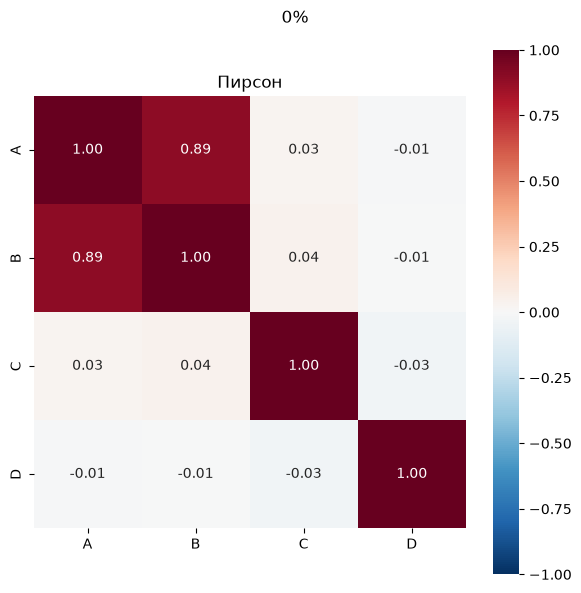

50%


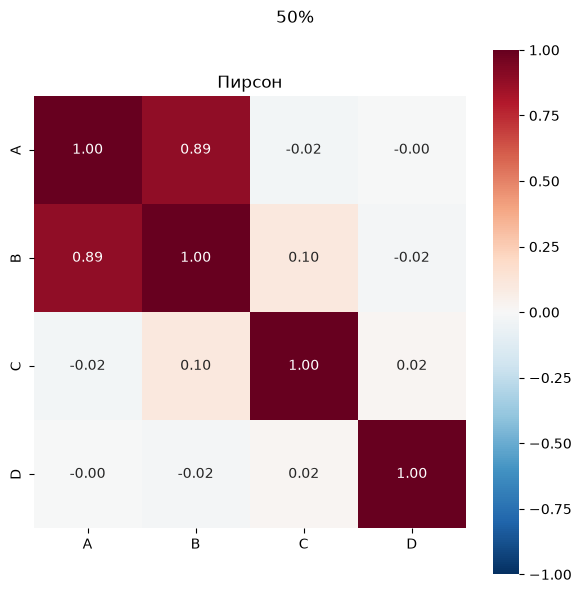

50% meadian


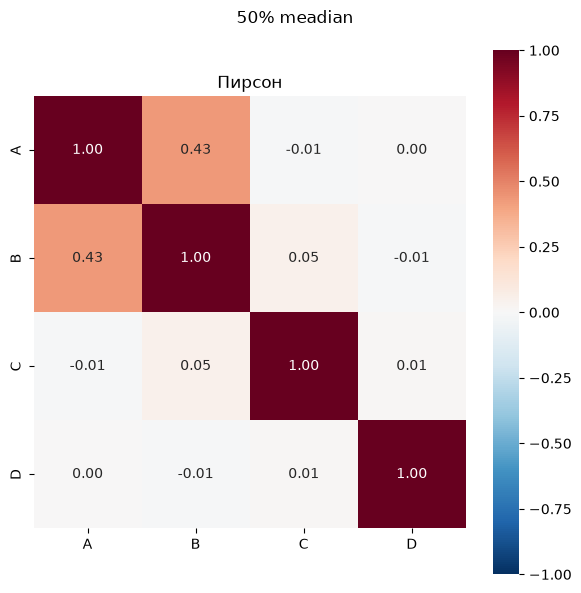

50% knn


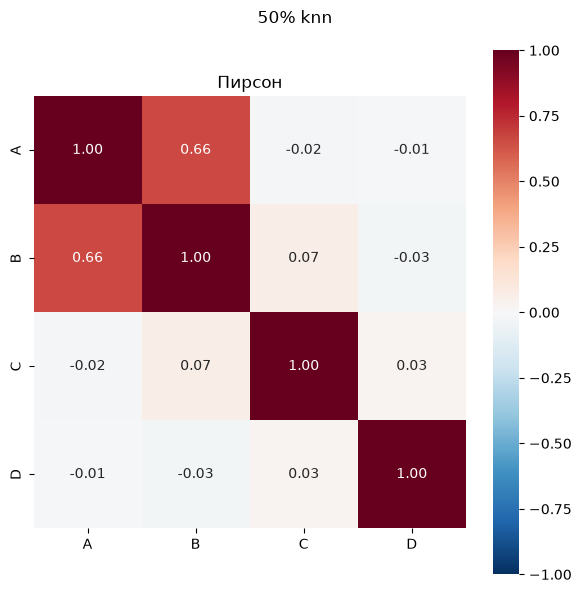

50% Regression


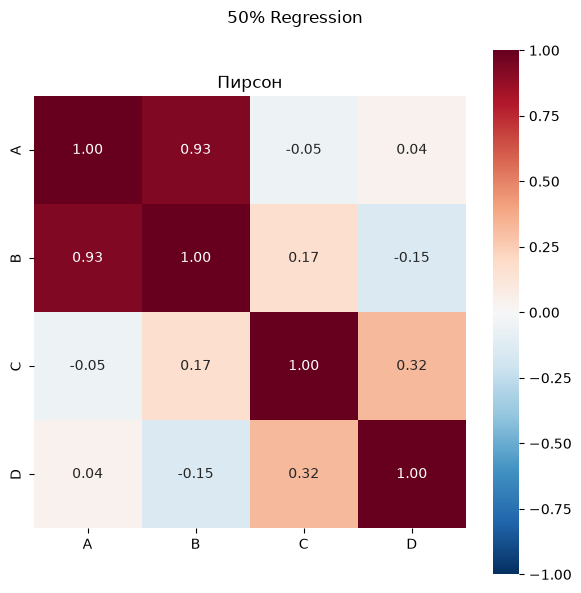

50% MICE


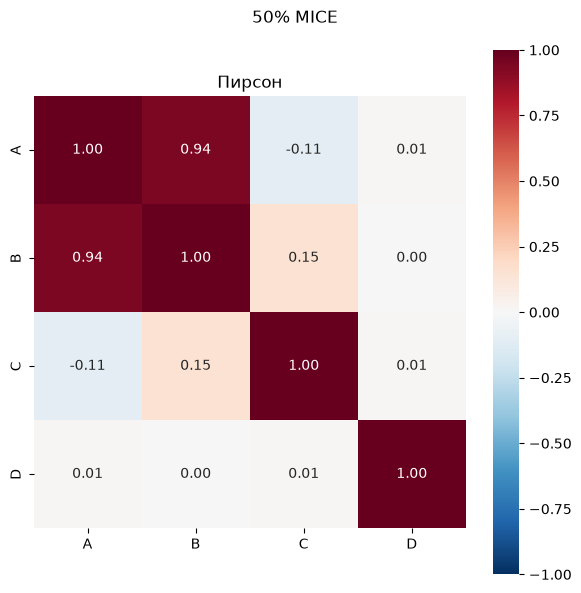

In [137]:
FEATURES = ['A', 'B', 'C', 'D']
KW = dict(annot=True, fmt='.2f', cmap='RdBu_r',
          vmin=-1, vmax=1, center=0, square=True)

datasets = {
    '0%':  dfS00,
    '50%':  dfS50,
    '50% meadian':  dfS50med,
    '50% knn': dfS50knn,
    '50% Regression': dfS50reg,
    '50% MICE': dfS50mice
}

for name, df_ in datasets.items():
    print(name)
    fig, ax = plt.subplots(figsize=(6, 6))
    fig.suptitle(name)
    sns.heatmap(df_[FEATURES].corr(method='pearson'),  ax=ax, **KW).set_title('Пирсон')
    plt.tight_layout()
    plt.show()

0%


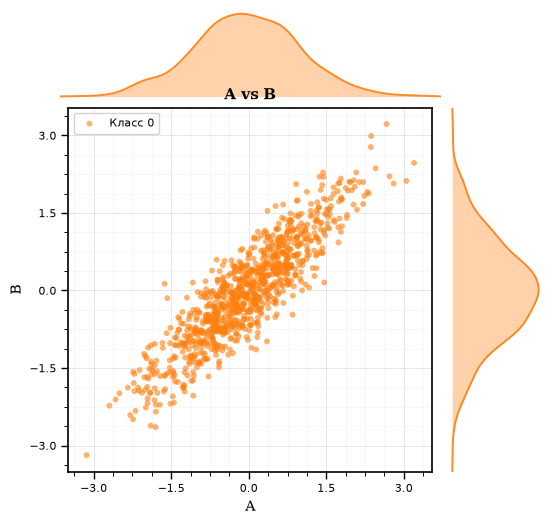

50%


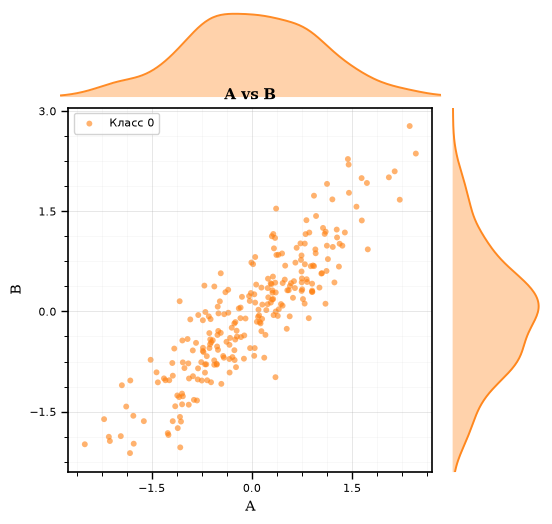

50% meadian


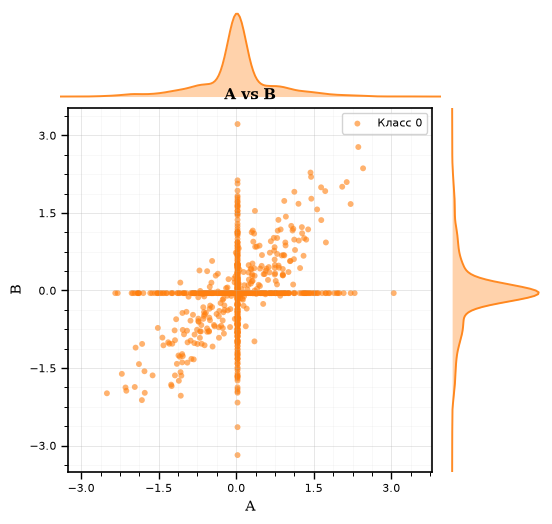

50% knn


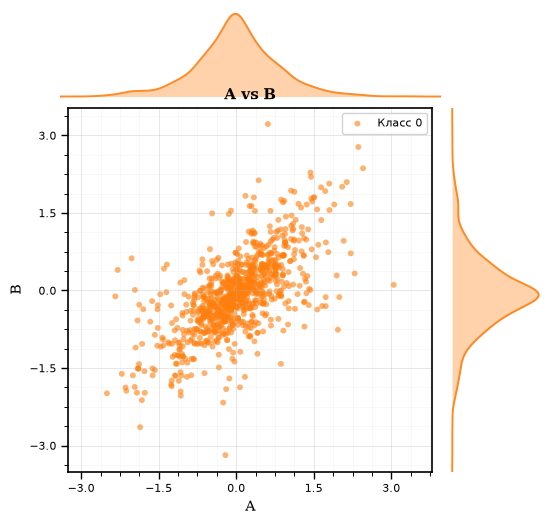

50% Regression


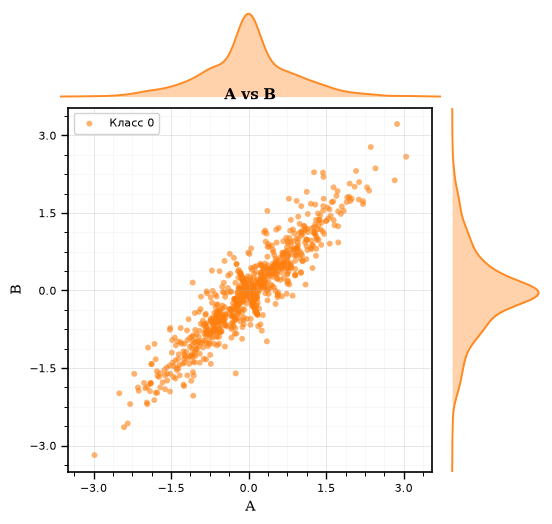

50% MICE


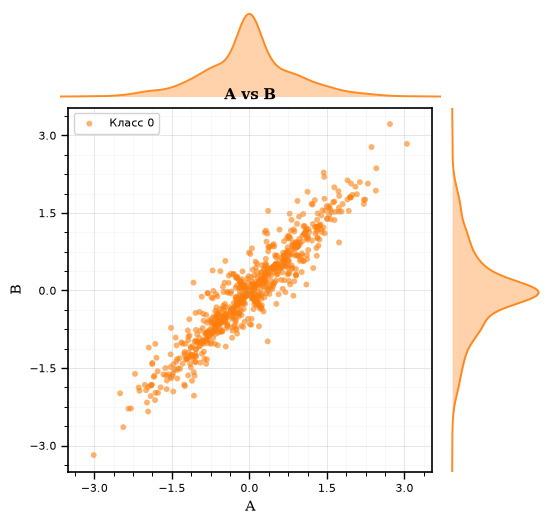

----------------------------------------
0%


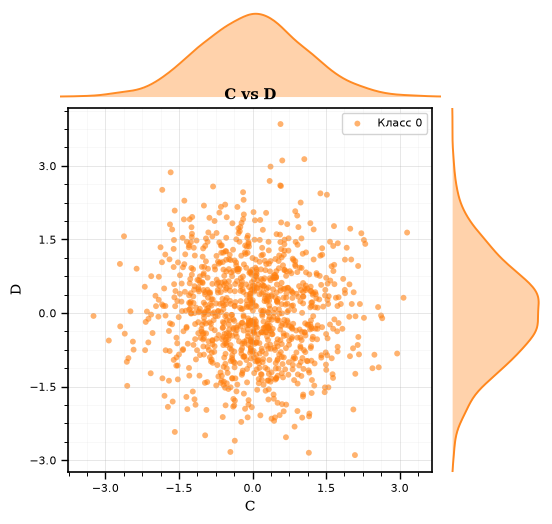

50%


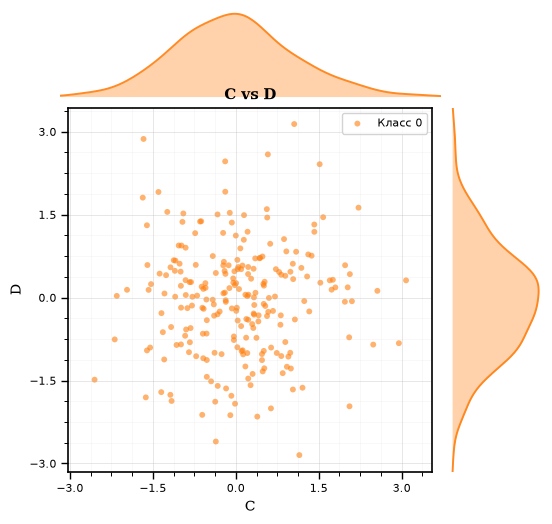

50% meadian


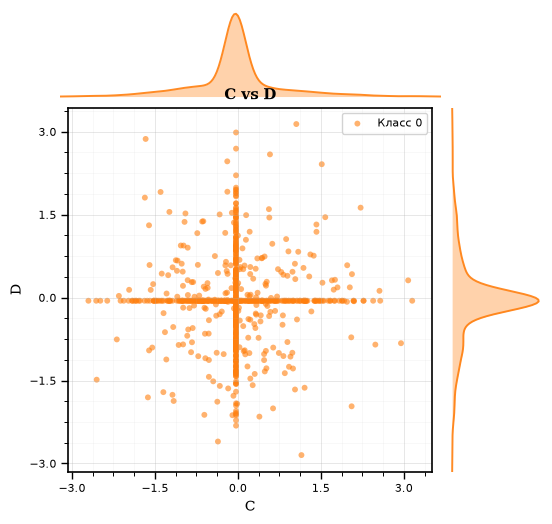

50% knn


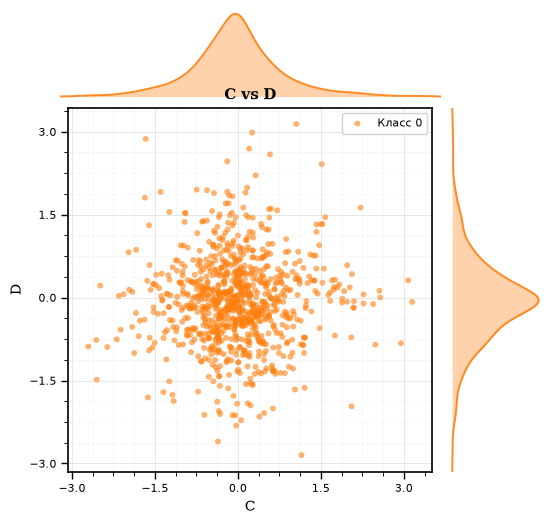

50% Regression


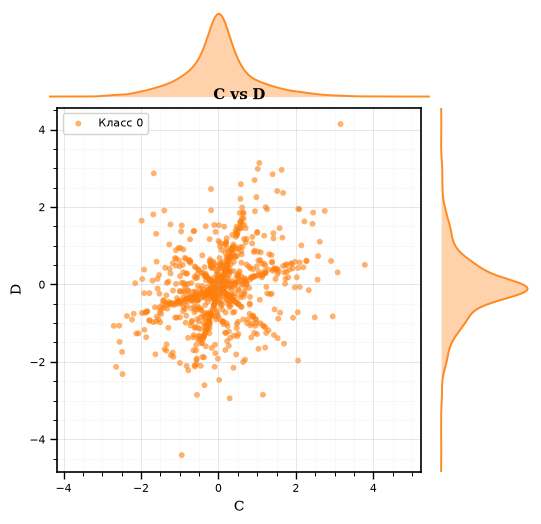

50% MICE


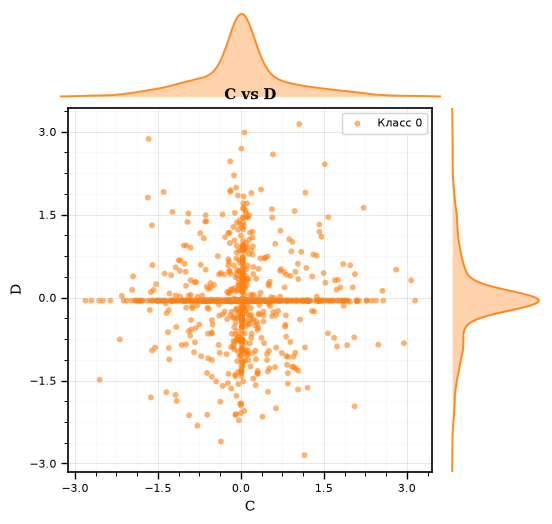

In [138]:
for name, df_ in datasets.items():
    print(name)
    plot_2d_visualization(
        df=df_,
        features=['A', 'B'],
        class_column='class',
        figsize=(6, 6),
        n_classes=1,
        colors=['tab:orange'],
        markers=['o'],
        axis_linewidth=1.2,
        tick_width=1.0,
        tick_length_major=5,
        tick_length_minor=3,
        n_major_ticks=5,
        minor_per_major=4,
        grid=True, grid_alpha=0.3,
        grid_major_lw=0.7, grid_minor_lw=0.4,
        square=True,
        title_fontsize=11, title_fontweight='bold',
        title_fontfamily='DejaVu Serif',
        label_fontsize=10, label_fontfamily='DejaVu Serif',
        tick_fontsize=8,   tick_fontfamily='DejaVu Sans Mono',
        legend_fontsize=8, legend_fontfamily='DejaVu Sans',
        show_legend=True,
        show_title=True,
        alpha=0.6, marker_size=18,
        show_density=True, show_density_x=True, show_density_y=True,
        density_alpha=0.35, density_linealpha=0.9,
        density_linewidth=1.4, density_bins=200,
    )
print('----------------------------------------')
for name, df_ in datasets.items():
    print(name)
    plot_2d_visualization(
        df=df_,
        features=['C', 'D'],
        class_column='class',
        figsize=(6, 6),
        n_classes=1,
        colors=['tab:orange'],
        markers=['o'],
        axis_linewidth=1.2,
        tick_width=1.0,
        tick_length_major=5,
        tick_length_minor=3,
        n_major_ticks=5,
        minor_per_major=4,
        grid=True, grid_alpha=0.3,
        grid_major_lw=0.7, grid_minor_lw=0.4,
        square=True,
        title_fontsize=11, title_fontweight='bold',
        title_fontfamily='DejaVu Serif',
        label_fontsize=10, label_fontfamily='DejaVu Serif',
        tick_fontsize=8,   tick_fontfamily='DejaVu Sans Mono',
        legend_fontsize=8, legend_fontfamily='DejaVu Sans',
        show_legend=True,
        show_title=True,
        alpha=0.6, marker_size=18,
        show_density=True, show_density_x=True, show_density_y=True,
        density_alpha=0.35, density_linealpha=0.9,
        density_linewidth=1.4, density_bins=200,
    )

[1.9] Для каждого из датасетов из пункта [1.8], включая исходный dfSd00, выполнить в
форме Upset plot визуализацию (а) чисел объектов с пропущенными значениями для
всех вариантов группировки пропусков по признакам, (б) чисел объектов с
совпадающими значениями по признакам для всех вариантов группировки признаков.

In [139]:
def draw_upset(conditions, title):
    set_names = list(conditions.keys())
    n_sets = len(set_names)
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728',
              '#9467bd', '#8c564b', '#e377c2', '#7f7f7f',
              '#bcbd22', '#17becf'][:n_sets]

    # intersections = {}
    # for r in range(1, n_sets + 1):
    #     for combo in combinations(range(n_sets), r):
    #         mask = conditions[set_names[combo[0]]]
    #         for i in range(1, len(combo)):
    #             mask = mask & conditions[set_names[combo[i]]]
    #         size = int(mask.sum())
    #         if size > 0:
    #             intersections[combo] = size
    intersections = {}

    for r in range(1, n_sets + 1):
        for combo in combinations(range(n_sets), r):

            mask = np.ones(len(conditions[set_names[0]]), dtype=bool)

            for i in range(n_sets):
                if i in combo:
                    mask = mask & conditions[set_names[i]]
                else:
                    mask = mask & ~conditions[set_names[i]]

            size = int(mask.sum())

            if size > 0:
                intersections[combo] = size

    if not intersections:
        print(f"[{title}] нет непустых пересечений — пропуск")
        return

    # sorted_intersections = sorted(intersections.items(),
    #                               key=lambda x: x[1], reverse=True)
    # Сортировка по количеству множеств в пересечении
    sorted_intersections = sorted(intersections.items(),
                                  key=lambda x: len(x[0]))

    plot_sizes = [item[1] for item in sorted_intersections]
    plot_matrix = np.array(
        [[1 if i in combo else 0 for i in range(n_sets)]
         for combo, _ in sorted_intersections]
    ).T

    fig = plt.figure(figsize=(14, 9))
    gs = fig.add_gridspec(2, 2, width_ratios=[2, 5],
                          height_ratios=[3, 2], hspace=0.05, wspace=0.05)

    ax_sets   = fig.add_subplot(gs[1, 0])
    ax_bar    = fig.add_subplot(gs[0, 1])
    ax_matrix = fig.add_subplot(gs[1, 1])

    set_totals = [int(conditions[name].sum()) for name in set_names]
    y_pos_sets = np.arange(n_sets)
    max_total = max(set_totals) if max(set_totals) > 0 else 1

    ax_sets.barh(y_pos_sets, [-t for t in set_totals],
                 color=colors, edgecolor='white', linewidth=1)
    ax_sets.set_yticks(y_pos_sets)
    ax_sets.set_yticklabels([])
    ax_sets.set_ylim(-0.5, n_sets - 0.5)
    ax_sets.invert_yaxis()
    ax_sets.set_xlim(-max_total * 1.4, 0)
    ax_sets.set_xlabel('Set size', fontweight='bold', fontsize=11)
    ax_sets.spines['top'].set_visible(False)
    ax_sets.spines['right'].set_visible(False)
    ax_sets.spines['bottom'].set_visible(False)
    ax_sets.tick_params(axis='y', length=0)
    ax_sets.tick_params(axis='x', labelbottom=False)

    for i, total in enumerate(set_totals):
        ax_sets.text(-total - max_total * 0.02, i, str(total),
                     va='center', ha='right', fontweight='bold', fontsize=9)
    for i, name in enumerate(set_names):
        ax_sets.text(-max_total * 1.42, i, name,
                     va='center', ha='right', fontweight='bold',
                     fontsize=10, color=colors[i])

    y_pos_bar = np.arange(len(plot_sizes))
    bars = ax_bar.bar(y_pos_bar, plot_sizes,
                      color='#4472C4', edgecolor='white', linewidth=0.5)
    ax_bar.set_ylabel('Objects', fontweight='bold', fontsize=11)
    ax_bar.set_ylim(0, max(plot_sizes) * 1.15)
    ax_bar.set_xlim(-0.5, len(plot_sizes) - 0.5)
    ax_bar.spines['top'].set_visible(False)
    ax_bar.spines['right'].set_visible(False)
    ax_bar.spines['bottom'].set_visible(False)
    ax_bar.tick_params(axis='x', bottom=False, labelbottom=False)

    for bar, size in zip(bars, plot_sizes):
        height = bar.get_height()
        ax_bar.text(bar.get_x() + bar.get_width() / 2., height,
                    f'{size}', ha='center', va='bottom',
                    fontsize=8, fontweight='bold')

    for i in range(n_sets):
        bg_color = '#F5F5F5' if i % 2 == 0 else '#E8E8E8'
        ax_matrix.axhspan(i - 0.5, i + 0.5, color=bg_color, zorder=0)

    for col_idx in range(len(plot_sizes)):
        y_coords = np.where(plot_matrix[:, col_idx] == 1)[0]
        if len(y_coords) > 0:
            ax_matrix.plot([col_idx, col_idx],
                           [y_coords[0], y_coords[-1]],
                           color='#404040', linewidth=2.5,
                           zorder=2, solid_capstyle='round')
        for row_idx in range(n_sets):
            if row_idx in y_coords:
                ax_matrix.scatter(col_idx, row_idx,
                                  color=colors[row_idx], s=100, zorder=3)
            else:
                ax_matrix.scatter(col_idx, row_idx,
                                  color='#D0D0D0', s=60,
                                  zorder=1, alpha=0.6)

    ax_matrix.set_yticks(y_pos_sets)
    ax_matrix.set_yticklabels([])
    ax_matrix.set_ylim(-0.5, n_sets - 0.5)
    ax_matrix.invert_yaxis()
    ax_matrix.set_xlim(-0.5, len(plot_sizes) - 0.5)
    ax_matrix.tick_params(axis='x', bottom=False, labelbottom=False)
    ax_matrix.spines['top'].set_visible(False)
    ax_matrix.spines['right'].set_visible(False)
    ax_matrix.spines['bottom'].set_visible(False)
    ax_matrix.set_xlabel('Intersections', fontsize=9, style='italic')

    plt.suptitle(title, fontsize=13, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()


===== Датасет: dfS00 =====
[dfS00] (а) пропусков нет — график не строится
[dfS00] (б) Все значения уникальны — график не строится

===== Датасет: dfS50 =====


/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


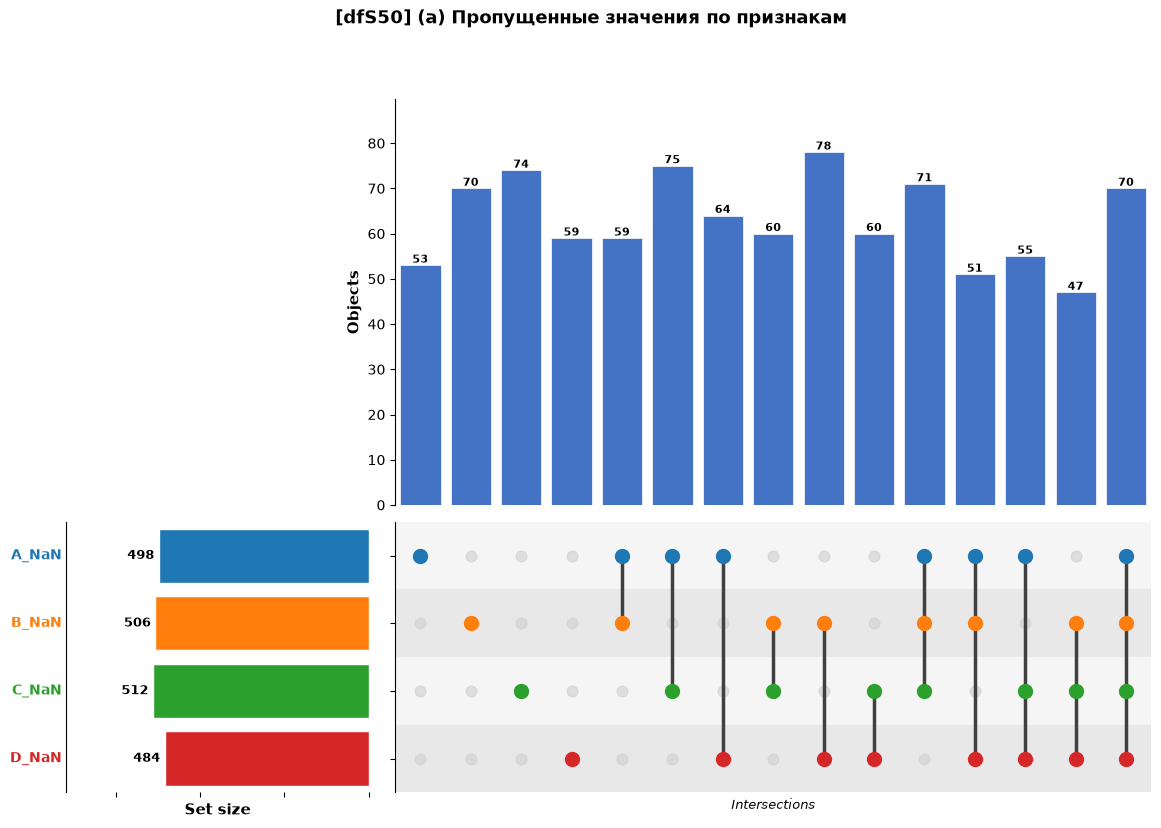

/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


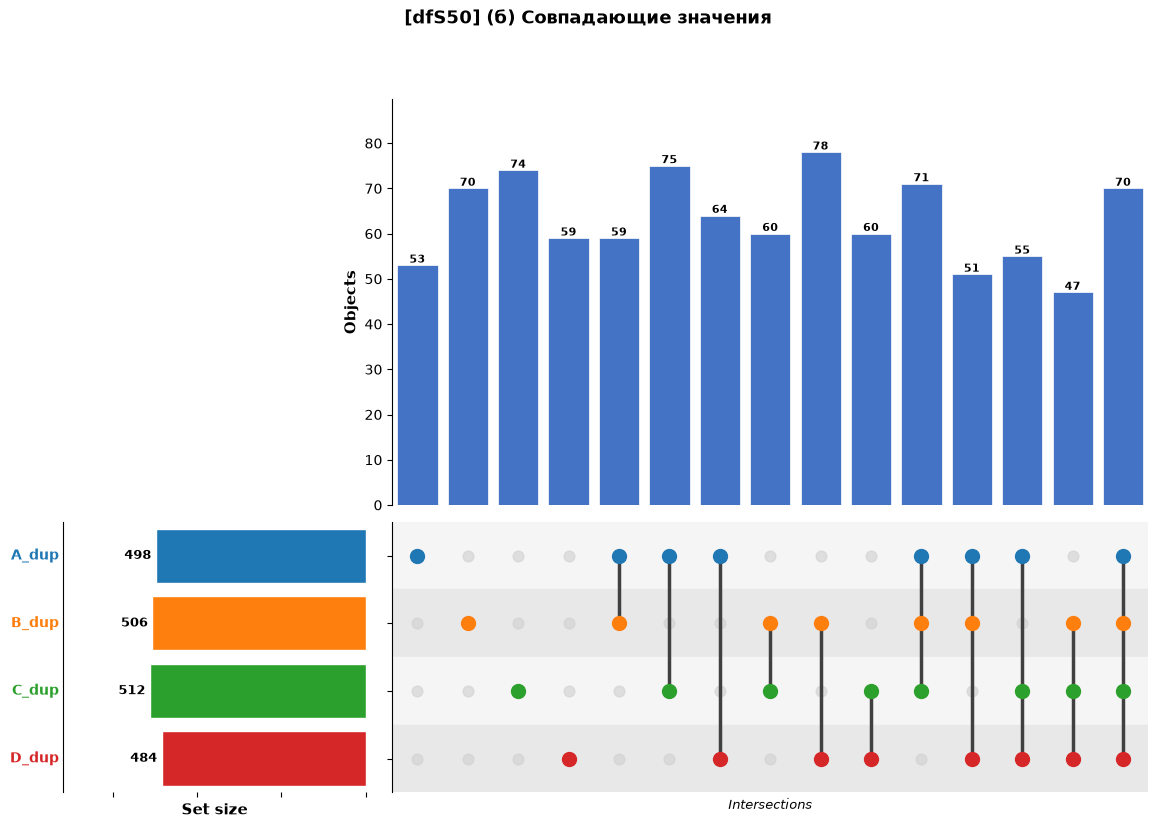

/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



===== Датасет: dfSd50med =====
[dfSd50med] (а) пропусков нет — график не строится


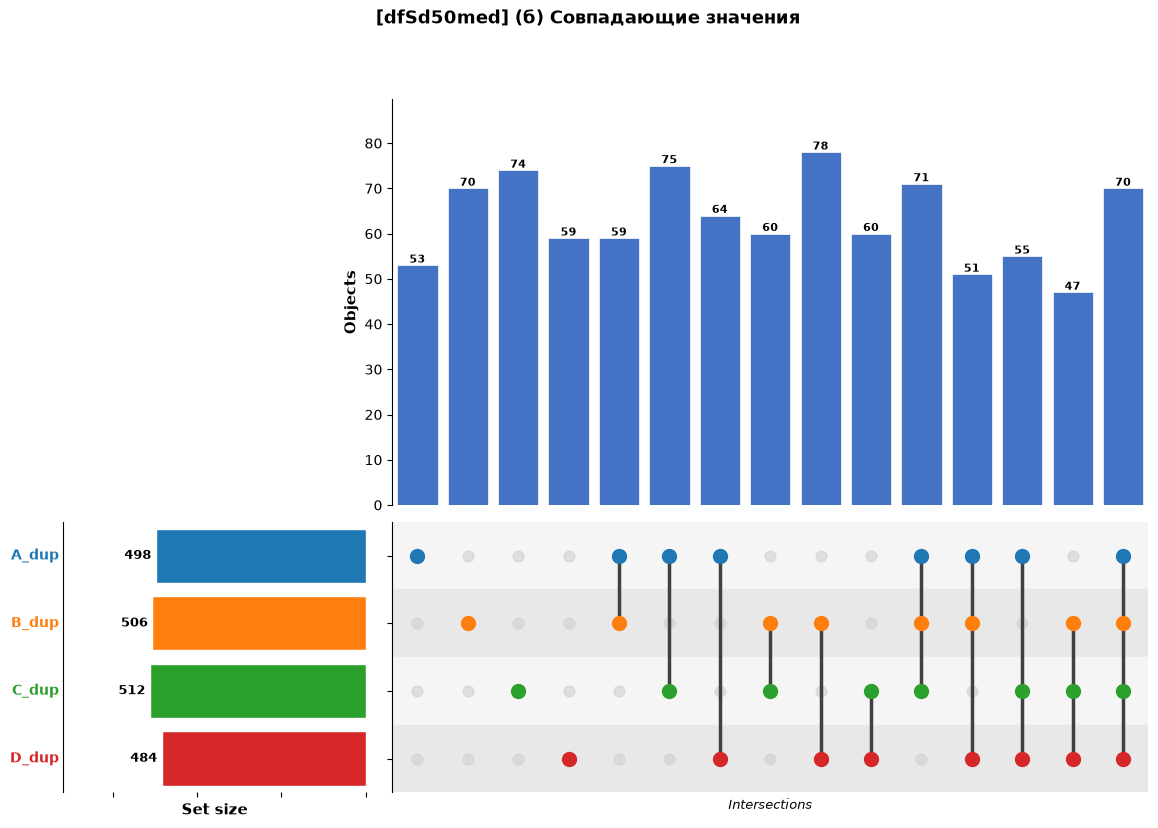


===== Датасет: dfS50knn =====
[dfS50knn] (а) пропусков нет — график не строится


/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


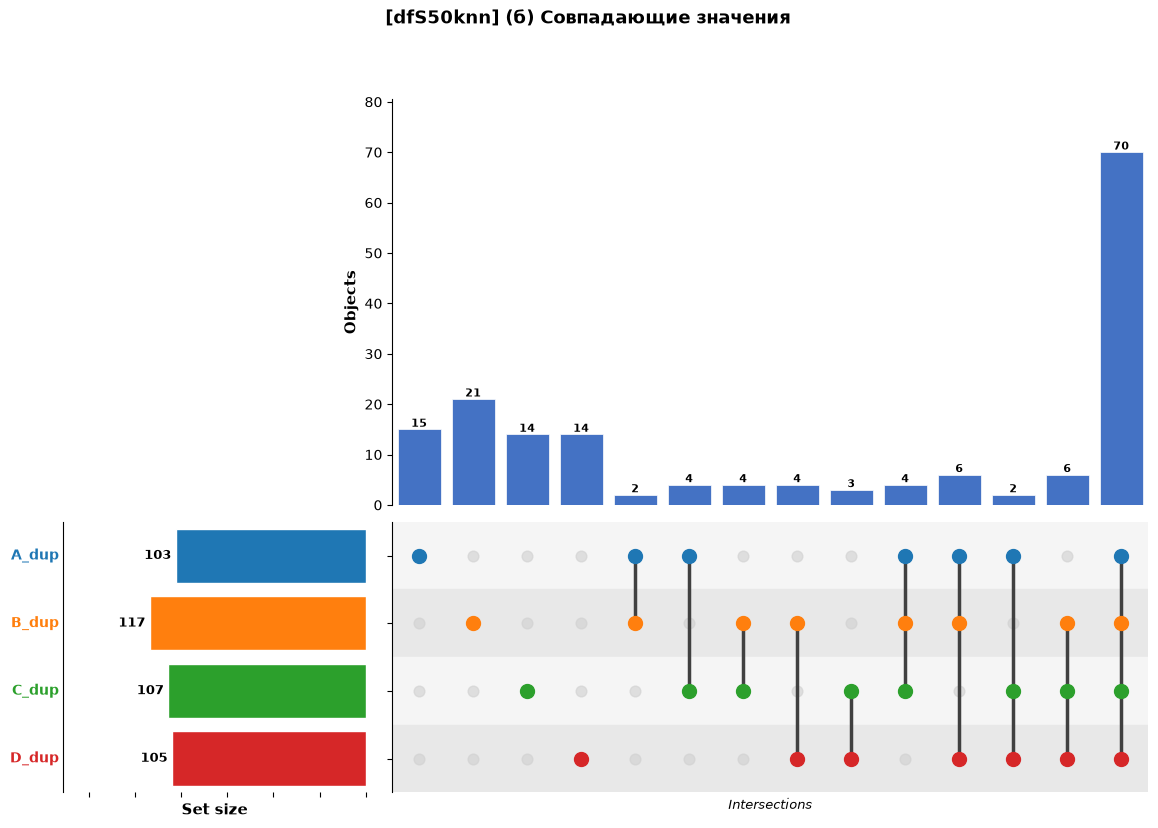

/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



===== Датасет: dfS50reg =====
[dfS50reg] (а) пропусков нет — график не строится


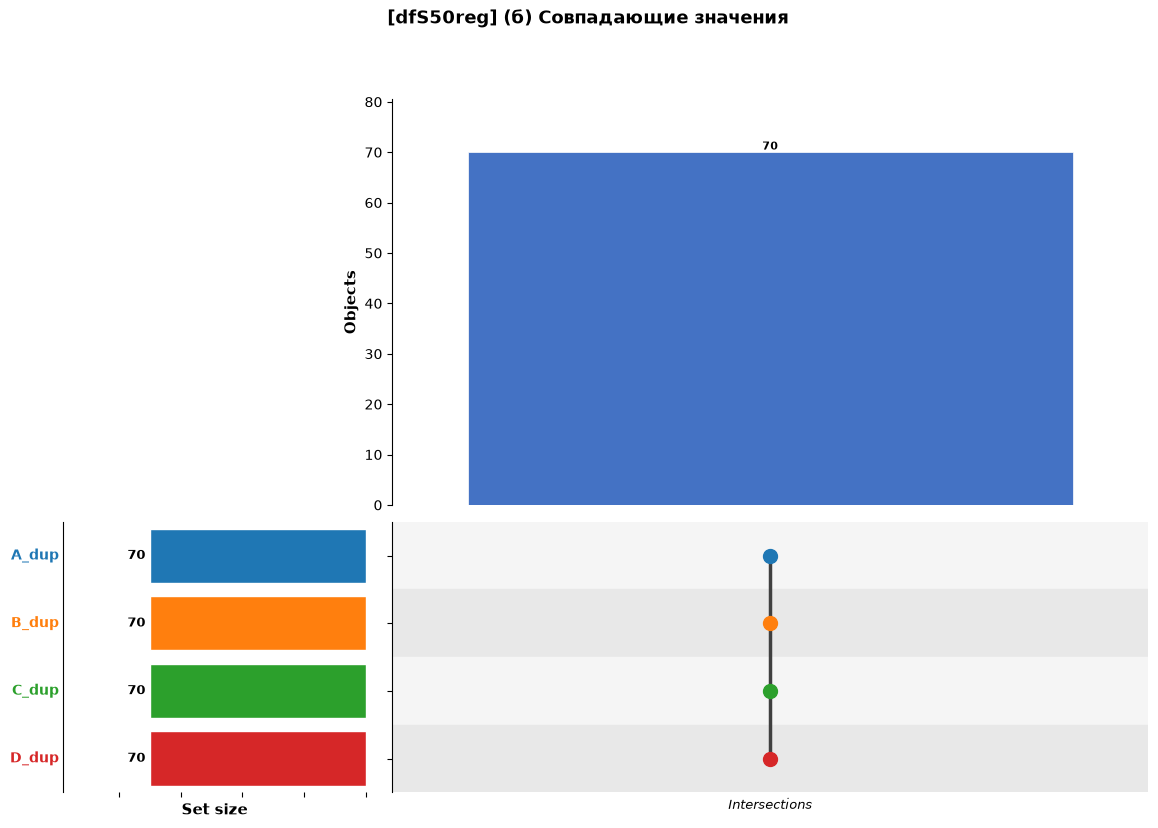


===== Датасет: dfS50mice =====
[dfS50mice] (а) пропусков нет — график не строится


/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


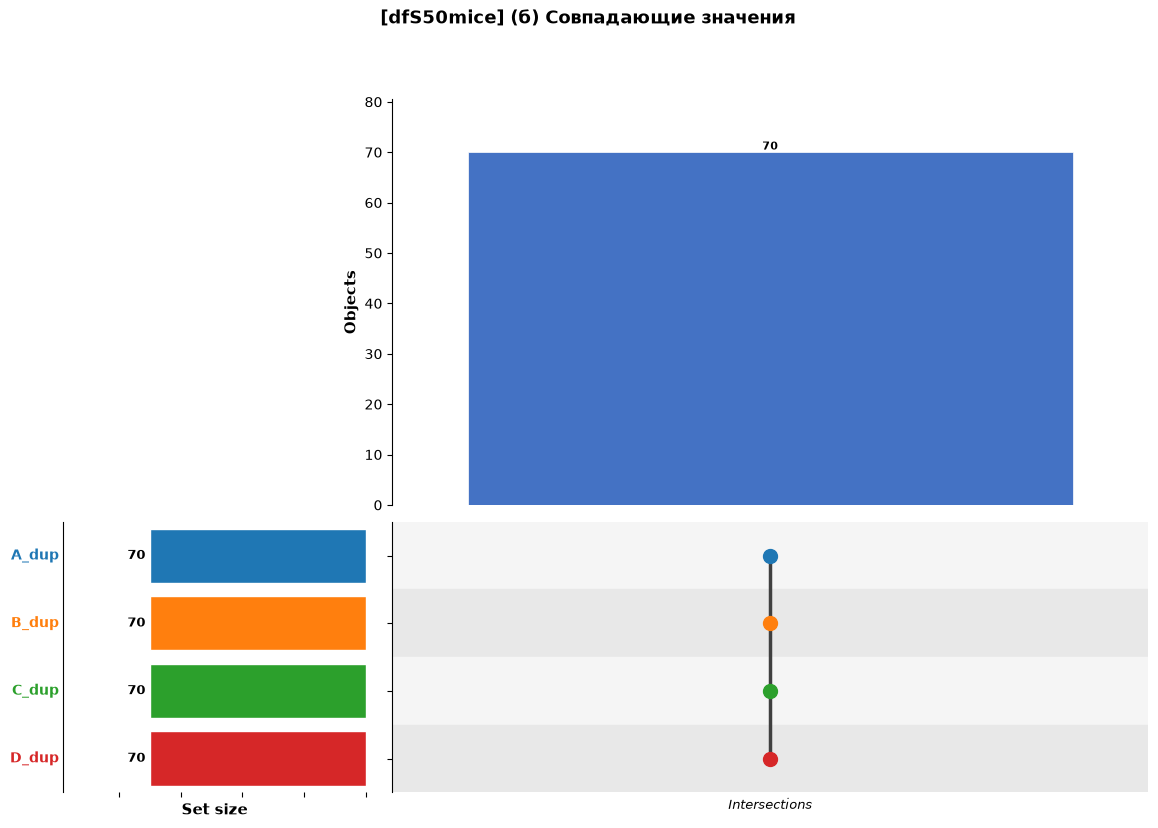

In [140]:
FEATURES = ['A', 'B', 'C', 'D']

datasets_19 = {
    'dfS00':        dfS00,
    'dfS50':        dfS50,
    'dfSd50med':    dfSd50med,
    'dfS50knn':     dfS50knn,
    'dfS50reg':     dfS50reg,
    'dfS50mice':    dfS50mice,
}

for name, df_ in datasets_19.items():
    print(f'\n===== Датасет: {name} =====')

    # ---------- (а) ПРОПУСКИ ----------
    miss_conditions = {f'{col}_NaN': df_[col].isna() for col in FEATURES}
    miss_conditions = {k: v for k, v in miss_conditions.items() if v.sum() > 0}

    if miss_conditions:
        draw_upset(miss_conditions,
                   f'[{name}] (а) Пропущенные значения по признакам')
    else:
        print(f"[{name}] (а) пропусков нет — график не строится")

    # ---------- (б) СОВПАДАЮЩИЕ ЗНАЧЕНИЯ ----------
    eq_conditions = {}
    for col in FEATURES:
        dup_mask = df_[col].duplicated(keep=False)
        if dup_mask.sum() > 0:
            eq_conditions[f'{col}_dup'] = dup_mask

    if eq_conditions:
        draw_upset(eq_conditions,
                f'[{name}] (б) Совпадающие значения')
    else:
        print(f"[{name}] (б) Все значения уникальны — график не строится")

[1.10]** На основе исходного датасета dfS00 клонировать датасет dfMNAR, в котором для
каждого объекта удалены все значения призаков C и D, которые меньше признаковой
медианы. Выполнить для полученного датасета пункты [1.8] и [1.9].

In [141]:
dfMNAR = dfS00.copy()

med_C = dfS00['C'].median()
med_D = dfS00['D'].median()

dfMNAR.loc[dfMNAR['C'] < med_C, 'C'] = np.nan
dfMNAR.loc[dfMNAR['D'] < med_D, 'D'] = np.nan

In [142]:
dfMNARmed = dfMNAR.copy()
dfMNARknn = dfMNAR.copy()
dfMNARreg = dfMNAR.copy()
dfMNARmice = dfMNAR.copy()

cols = ['A', 'B', 'C', 'D']

# медиана
med_C = dfMNAR['C'].median()
med_D = dfMNAR['D'].median()
dfMNARmed['C'] = dfMNARmed['C'].fillna(med_C)
dfMNARmed['D'] = dfMNARmed['D'].fillna(med_D)

# kNN-заполнение
knn_imputer = KNNImputer(n_neighbors=5)
knn_imputed = pd.DataFrame(knn_imputer.fit_transform(dfMNARknn[cols]), columns=cols, index=dfMNARknn.index)
knn_valC = knn_imputed['C']
knn_valD = knn_imputed['D']
dfMNARknn['C'] = dfMNARknn['C'].fillna(knn_valC)
dfMNARknn['D'] = dfMNARknn['D'].fillna(knn_valD)

# регрессионное заполнение
reg_imputer = IterativeImputer(estimator=LinearRegression(), max_iter=500, random_state=0)
reg_imputed = pd.DataFrame(reg_imputer.fit_transform(dfMNARreg[cols]), columns=cols, index=dfMNARreg.index)
reg_valC = reg_imputed['C']
reg_valD = reg_imputed['D']
dfMNARreg['C'] = dfMNARreg['C'].fillna(reg_valC)
dfMNARreg['D'] = dfMNARreg['D'].fillna(reg_valD)

# MICE
mice_imputer = IterativeImputer(max_iter=500, random_state=0)
mice_imputed = pd.DataFrame(mice_imputer.fit_transform(dfMNARmice[cols]), columns=cols, index=dfMNARmice.index)
mice_valC = mice_imputed['C']
mice_valD = mice_imputed['D']
dfMNARmice['C'] = dfMNARmice['C'].fillna(mice_valC)
dfMNARmice['D'] = dfMNARmice['D'].fillna(mice_valD)

с пропусками


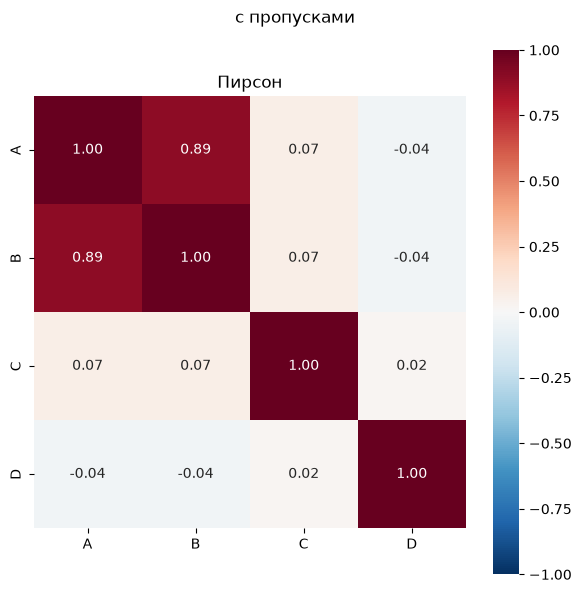

median


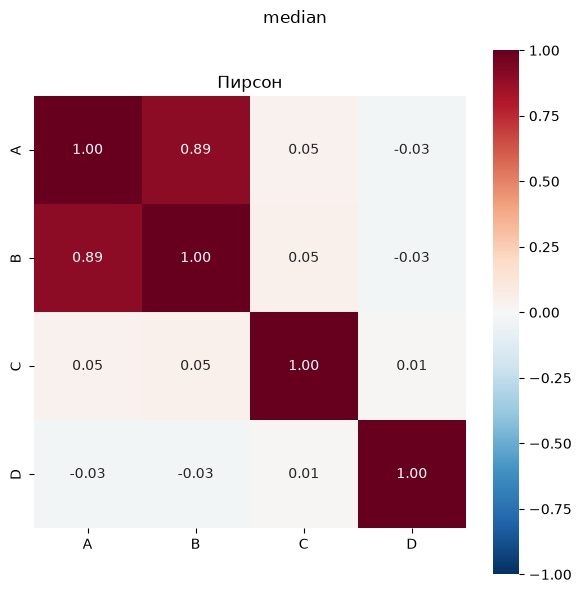

knn


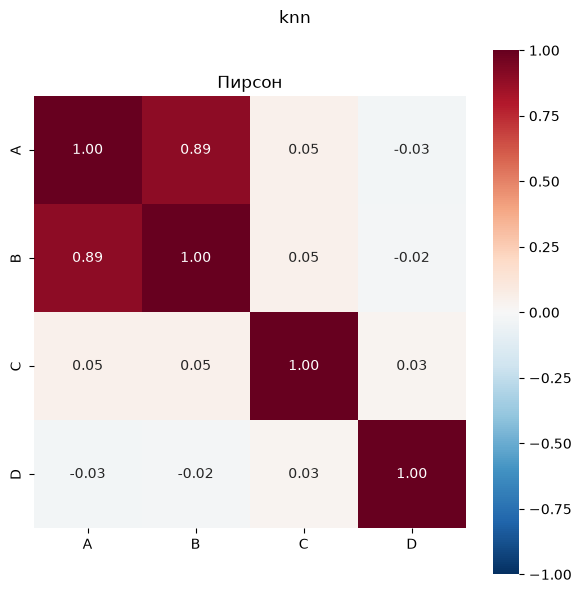

regression


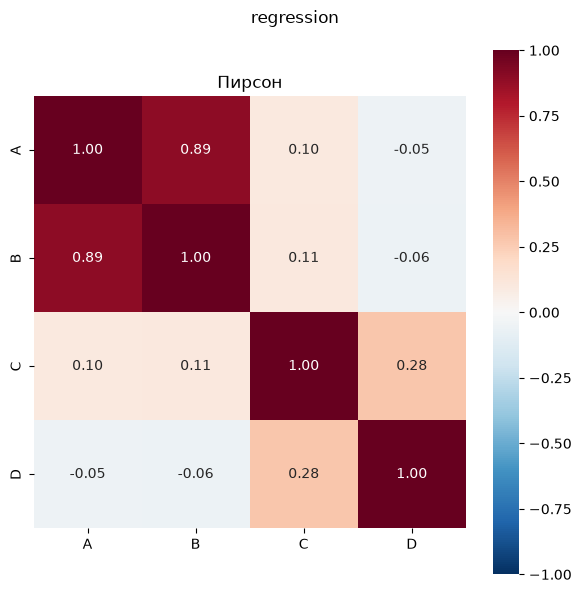

MICE


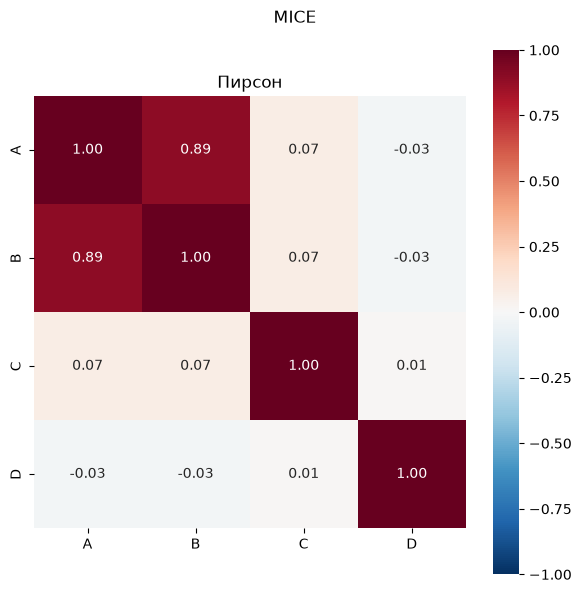

In [143]:
FEATURES = ['A', 'B', 'C', 'D']
KW = dict(annot=True, fmt='.2f', cmap='RdBu_r',
          vmin=-1, vmax=1, center=0, square=True)

datasets = {
    'с пропусками':  dfMNAR,
    'median':  dfMNARmed,
    'knn': dfMNARknn,
    'regression': dfMNARreg,
    'MICE': dfMNARmice
}

for name, df_ in datasets.items():
    print(name)
    fig, ax = plt.subplots(figsize=(6, 6))
    fig.suptitle(name)
    sns.heatmap(df_[FEATURES].corr(method='pearson'),  ax=ax, **KW).set_title('Пирсон')
    plt.tight_layout()
    plt.show()

с пропусками


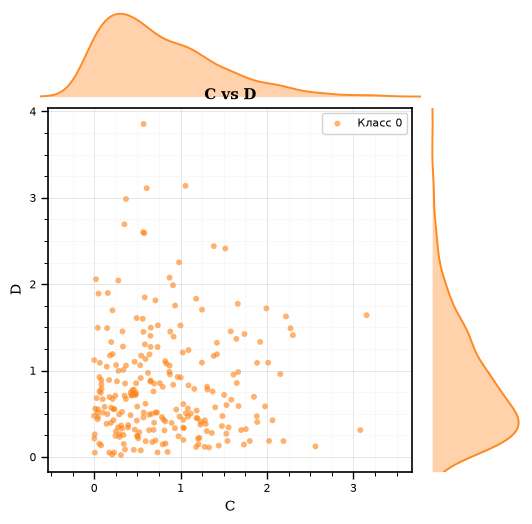

median


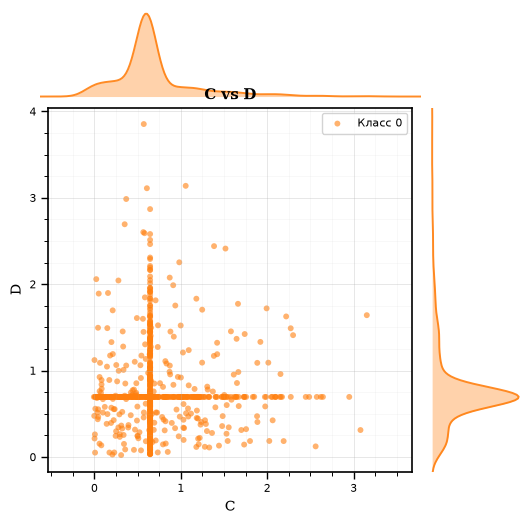

knn


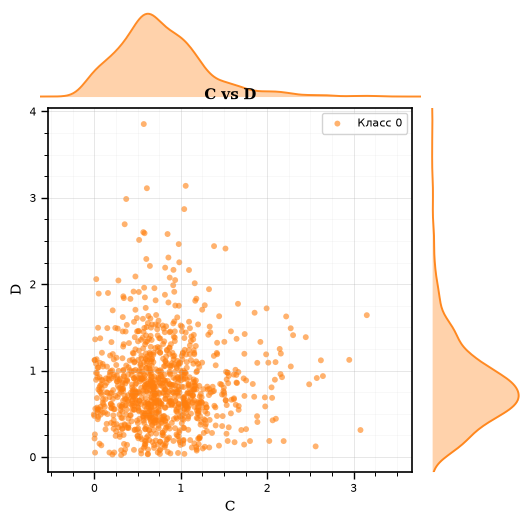

regression


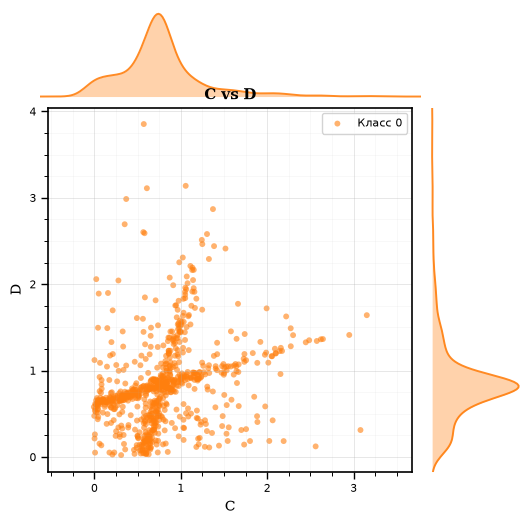

MICE


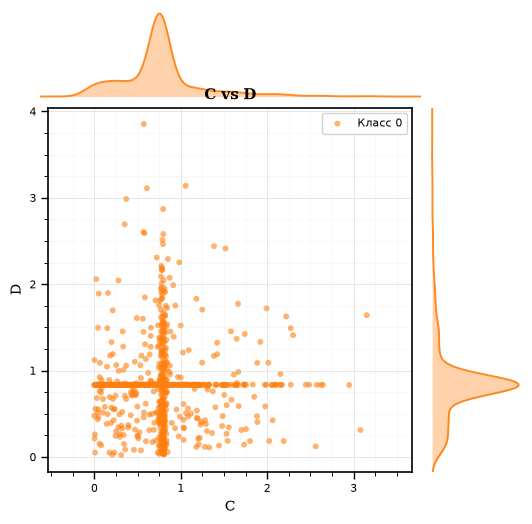

In [144]:
for name, df_ in datasets.items():
    print(name)
    plot_2d_visualization(
        df=df_,
        features=['C', 'D'],
        class_column='class',
        figsize=(6, 6),
        n_classes=1,
        colors=['tab:orange'],
        markers=['o'],
        axis_linewidth=1.2,
        tick_width=1.0,
        tick_length_major=5,
        tick_length_minor=3,
        n_major_ticks=5,
        minor_per_major=4,
        grid=True, grid_alpha=0.3,
        grid_major_lw=0.7, grid_minor_lw=0.4,
        square=True,
        title_fontsize=11, title_fontweight='bold',
        title_fontfamily='DejaVu Serif',
        label_fontsize=10, label_fontfamily='DejaVu Serif',
        tick_fontsize=8,   tick_fontfamily='DejaVu Sans Mono',
        legend_fontsize=8, legend_fontfamily='DejaVu Sans',
        show_legend=True,
        show_title=True,
        alpha=0.6, marker_size=18,
        show_density=True, show_density_x=True, show_density_y=True,
        density_alpha=0.35, density_linealpha=0.9,
        density_linewidth=1.4, density_bins=200,
    )


===== Датасет: с пропусками =====


/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


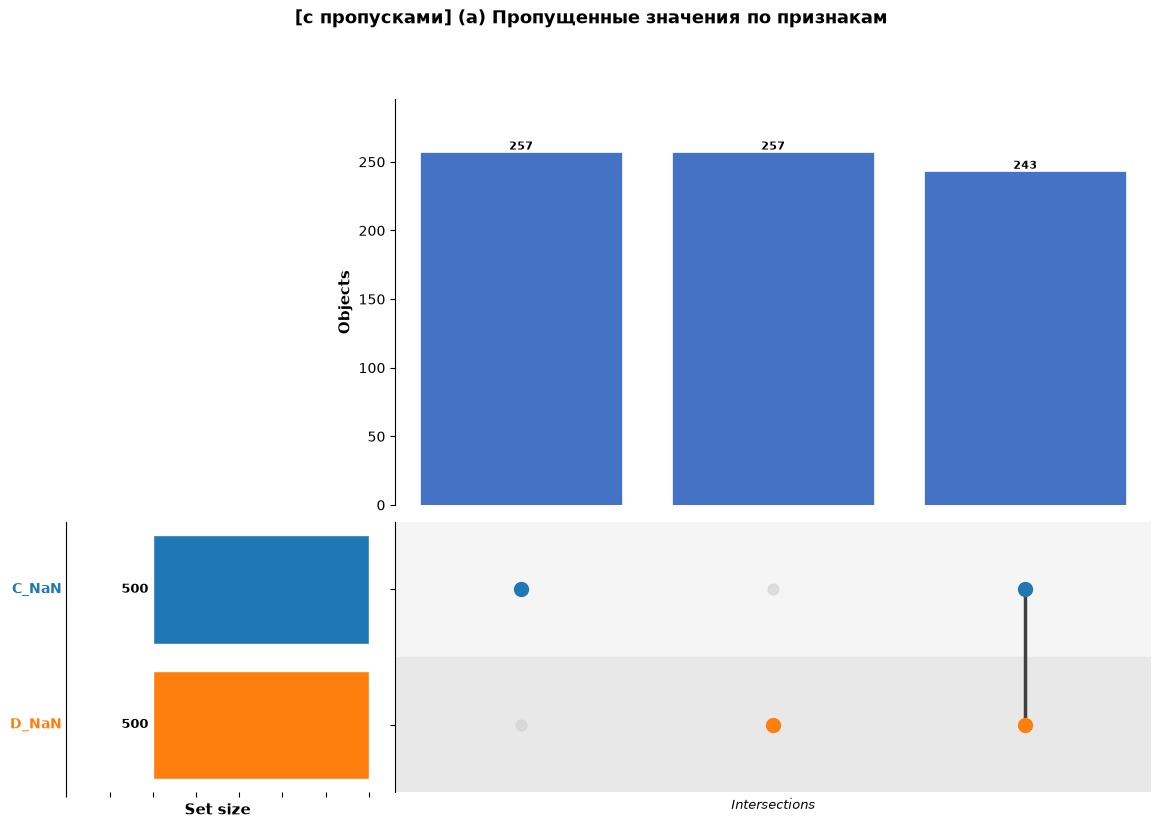

/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


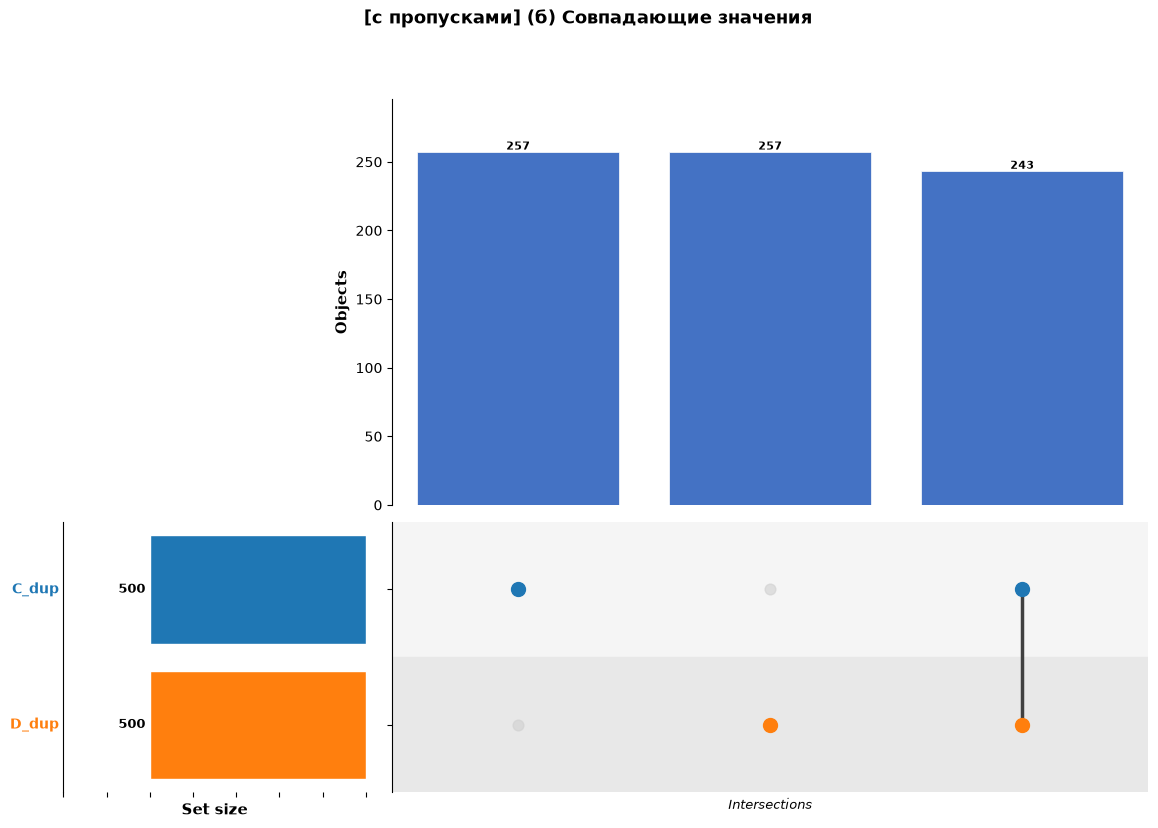


===== Датасет: median =====
[median] (а) пропусков нет — график не строится


/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


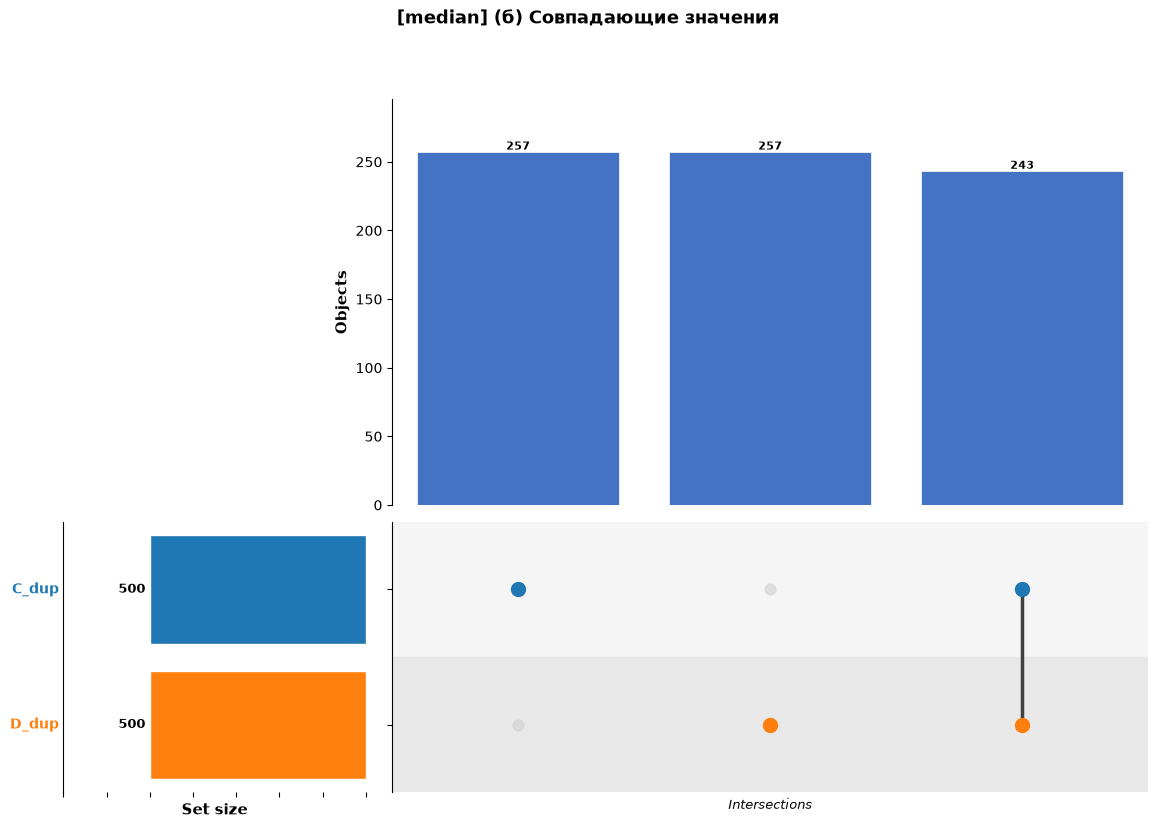


===== Датасет: knn =====
[knn] (а) пропусков нет — график не строится


/var/folders/r1/6w6kvsz558340ghc22d4yxq40000gn/T/ipykernel_2611/3111205432.py:134: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


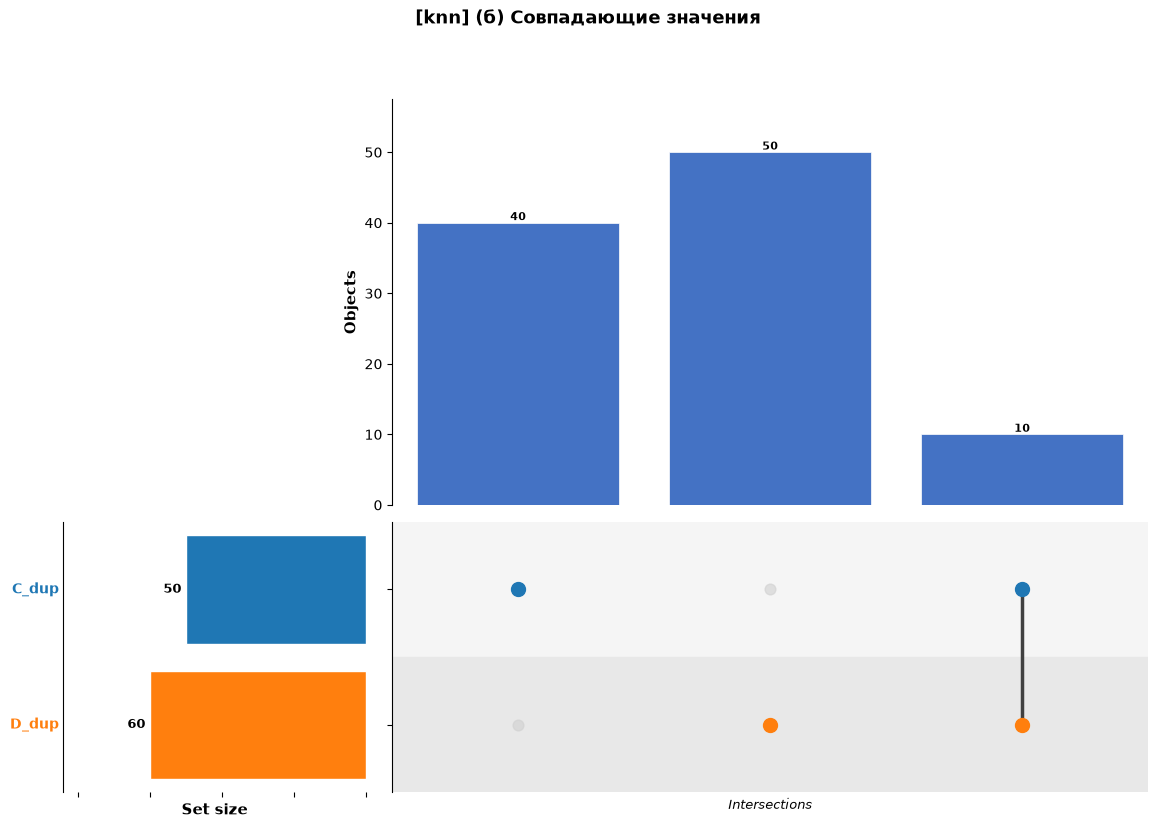


===== Датасет: regression =====
[regression] (а) пропусков нет — график не строится
[regression] (б) Все значения уникальны — график не строится

===== Датасет: MICE =====
[MICE] (а) пропусков нет — график не строится
[MICE] (б) Все значения уникальны — график не строится


In [145]:
FEATURES = ['A', 'B', 'C', 'D']

for name, df_ in datasets.items():
    print(f'\n===== Датасет: {name} =====')

    # ---------- (а) ПРОПУСКИ ----------
    miss_conditions = {f'{col}_NaN': df_[col].isna() for col in FEATURES}
    miss_conditions = {k: v for k, v in miss_conditions.items() if v.sum() > 0}

    if miss_conditions:
        draw_upset(miss_conditions,
                   f'[{name}] (а) Пропущенные значения по признакам')
    else:
        print(f"[{name}] (а) пропусков нет — график не строится")

    # ---------- (б) СОВПАДАЮЩИЕ ЗНАЧЕНИЯ ----------
    eq_conditions = {}
    for col in FEATURES:
        dup_mask = df_[col].duplicated(keep=False)
        if dup_mask.sum() > 0:
            eq_conditions[f'{col}_dup'] = dup_mask
    
    if eq_conditions:
        draw_upset(eq_conditions,
                    f'[{name}] (б) Совпадающие значения')
    else:
        print(f"[{name}] (б) Все значения уникальны — график не строится")